# **AI METHODS I: Group 5**
----
## Day1: Data cleaning and Exploratory Data Analysis (EDA)

### Goals

1. Load the dataset ""melbourne_house_prices.csv"" from Kaggle or upload csv using **pandas**.

    Steps:    
    a. Choose a python environment    
    b. Set up / Install packages with **.pip** and **import as**                
    c. Set up folders with realitve paths so they can work in any computer     
    d. Import CSV file with **.read()**      
          
2. Inspect the dataset and write a short **dataset card** (source, content, limitations).        

    Steps:    
    a. **.shape** | Number of rows and columns     
    b. **.head()** | The first rows: what the values look like                  
    c. **.info()** | Column names, data types and how many values are *not* missing |   
    d. **.describe()** | Summary statistics (mean, min, max, quartiles…) 
      
3. Detect and fix the classic **data problems**:       
           
    Steps:     
    a. Make a copy of de dataframe with **.copy()**     
    b. Tidy columns names if it's necessary     
    c. Remove all duplicated values with **.duplicated()**       
    d. Get an overview of **missing values()**  
    e. Remove irrelevant columns with **drop.()**    
    f. Fix inconsistent data types and outliers.           


4. **Feature Engineering** 
     
    Steps:     
    a. Extract **temporal features** (If necessary)  
    b. **Create** more features depending on the **relation between existing features**.              
    c. Format or transform variables to ensure they are fully model-ready   

5. **Comparing** raw and clean data sets

6. **(EDA)** Exploring the data with **descriptive statistics** and **visualizations** (matplotlib + seaborn).

    Steps:      
    a.  **Univariate**: one variable at a time    
    b.  **Bivariate**: two variables together       
    c. **Multivariate**: several variables at once      

7. Save a clean, **model-ready dataset** 

### 1.a. Choose a python environment

In [1]:
# Choose python environment. If doesn't work use this in the terminal--->>   
# (1) python -m venv .venv 
# (2) .venv\Scripts\Activate.ps1

### 1.b. Set up / Install packages with **.pip** and **import as**

In [2]:
# Set-up/ install packages.
%pip install "kagglehub[pandas-datasets]" pandas numpy matplotlib seaborn scikit-learn

     ---------------------------------------- 0.0/40.4 kB ? eta -:--:--
     ---------- ----------------------------- 10.2/40.4 kB ? eta -:--:--
     ---------- ----------------------------- 10.2/40.4 kB ? eta -:--:--
     ---------- ----------------------------- 10.2/40.4 kB ? eta -:--:--
     -------------------------------------- 40.4/40.4 kB 241.2 kB/s eta 0:00:00
   ---------------------------------------- 0.0/135.1 kB ? eta -:--:--
   --------------------- ------------------ 71.7/135.1 kB 1.3 MB/s eta 0:00:01
   ------------------------------------ --- 122.9/135.1 kB 1.8 MB/s eta 0:00:01
   ------------------------------------ --- 122.9/135.1 kB 1.8 MB/s eta 0:00:01
   ------------------------------------ --- 122.9/135.1 kB 1.8 MB/s eta 0:00:01
   ------------------------------------ --- 122.9/135.1 kB 1.8 MB/s eta 0:00:01
   -------------------------------------- 135.1/135.1 kB 499.4 kB/s eta 0:00:00
   ---------------------------------------- 0.0/290.9 kB ? eta -:--:--
   -----

In [3]:
# Import installed packages/ libraries into environment?
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub as kh
import zipfile
from pathlib import Path

### 1.c. Files Set-Up for the Project
 
1. Set up folders with realitve paths so they can work in any computer. 
2. Set-up display options.
3. Save images as png in respective folders.

In [4]:
# Set-up folders --- data and figures --- relative paths to enable the notebook to work on any computer.

DATA_DIR = Path("data")      # raw and clean CSV files go here
FIG_DIR = Path("figures")    # exported plots go here
MODEL_DIR = Path("..") / "models"
DATASET_DIR = Path("..") / "dataset"   # the clustered dataset you publish

DATA_DIR.mkdir(exist_ok=True)  # create the folder if it does not exist yet
FIG_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)
DATASET_DIR.mkdir(exist_ok=True)


In [5]:
# pandas display options 
pd.set_option("display.max_columns", 50)                 # show every column, do not hide them with "..."
pd.set_option("display.float_format", "{:,.2f}".format)  # 1234567.891 -> 1,234,567.89

# plot style 
sns.set_theme(style="whitegrid", context="notebook")  # clean background with a light grid
plt.rcParams["figure.figsize"] = (10, 5)              # default size of every figure (width, height) in inches

# Seed for anything random (sampling): the same seed always gives the same "random" result,
# so everybody in class sees exactly the same numbers.
RANDOM_STATE = 42

In [6]:
# "save_fig()" exports plots as .png 
# Creating a function to call when we need to save a figure (plot during analysis) onto the computer.

def save_fig(name):
    # Save the current figure as a PNG inside FIG_DIR.
    # dpi = dots per inch (resolution). bbox_inches="tight" trims empty white borders.
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

### 1.d. Import CSV file with **.read()**

In [7]:
# Import csv file from data folder.
df = pd.read_csv(
    DATA_DIR / "melbourne_house_prices.csv"
)

# print info of imported csv data --- check
print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns")

Loaded 34,857 rows and 21 columns


# 2. Inspect the dataset

Steps:    
    a. **.shape** | Number of rows and columns     
    b. **.head()** | The first rows: what the values look like                  
    c. **.info()** | Column names, data types and how many values are *not* missing    
    d. **.describe()** | Summary statistics (mean, min, max, quartiles…) 

### Dataset card

| | |
|---|---|
| **Name** | Melbourne House Prices |
| **Source** | Kaggle, [Chaitanya Jamble](https://www.kaggle.com/datasets/anthonypino/melbourne-housing-market) |
| **Origin** |This data was scraped from publicly available results posted every week from Domain.com.au. A dataset for Melbourne's Housing Market. |
| **Size (raw)** | 34,857 Rows by 21 Columns |
| **Licence** | Check the *License* field on the Kaggle page before re-using the data in a publication |
| **Known limitations** | Missing data |

### 2.a. **.shape** | Number of rows and columns  

In [8]:
# Use shape to see number of rows and columns
df.shape

(34857, 21)

### 2.b. **.head()** | The first rows: what the values look like    

In [9]:
# The first 5 rows.
df.head()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,68 Studley St,2,h,NaN,SS,Jellis,3/09/2016,2.50,"3,067.00",2.00,1.00,1.00,126.00,NaN,NaN,Yarra City Council,-37.80,145.00,Northern Metropolitan,"4,019.00"
1,Abbotsford,85 Turner St,2,h,"1,480,000.00",S,Biggin,3/12/2016,2.50,"3,067.00",2.00,1.00,1.00,202.00,NaN,NaN,Yarra City Council,-37.80,145.00,Northern Metropolitan,"4,019.00"
2,Abbotsford,25 Bloomburg St,2,h,"1,035,000.00",S,Biggin,4/02/2016,2.50,"3,067.00",2.00,1.00,0.00,156.00,79.00,"1,900.00",Yarra City Council,-37.81,144.99,Northern Metropolitan,"4,019.00"
3,Abbotsford,18/659 Victoria St,3,u,NaN,VB,Rounds,4/02/2016,2.50,"3,067.00",3.00,2.00,1.00,0.00,NaN,NaN,Yarra City Council,-37.81,145.01,Northern Metropolitan,"4,019.00"
4,Abbotsford,5 Charles St,3,h,"1,465,000.00",SP,Biggin,4/03/2017,2.50,"3,067.00",3.00,2.00,0.00,134.00,150.00,"1,900.00",Yarra City Council,-37.81,144.99,Northern Metropolitan,"4,019.00"


### 2.c. **.info()** | Column names, data types and how many values are *not* missing

In [10]:
# Column names, data types (Dtype) and number of non-missing values per column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34857 entries, 0 to 34856
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         34857 non-null  object 
 1   Address        34857 non-null  object 
 2   Rooms          34857 non-null  int64  
 3   Type           34857 non-null  object 
 4   Price          27247 non-null  float64
 5   Method         34857 non-null  object 
 6   SellerG        34857 non-null  object 
 7   Date           34857 non-null  object 
 8   Distance       34856 non-null  float64
 9   Postcode       34856 non-null  float64
 10  Bedroom2       26640 non-null  float64
 11  Bathroom       26631 non-null  float64
 12  Car            26129 non-null  float64
 13  Landsize       23047 non-null  float64
 14  BuildingArea   13742 non-null  float64
 15  YearBuilt      15551 non-null  float64
 16  CouncilArea    34854 non-null  object 
 17  Lattitude      26881 non-null  float64
 18  Longti

### 2.d. **.describe()** | Summary statistics (mean, min, max, quartiles…)

In [11]:
# .T transposes the table (rows <-> columns) so it is easier to read with many columns
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Suburb,34857,351,Reservoir,844,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Address,34857,34009,5 Charles St,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rooms,"34,857.00",NaN,NaN,NaN,3.03,0.97,1.00,2.00,3.00,4.00,16.00
Type,34857,3,h,23980,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,"27,247.00",NaN,NaN,NaN,"1,050,173.34","641,467.13","85,000.00","635,000.00","870,000.00","1,295,000.00","11,200,000.00"
Method,34857,9,S,19744,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SellerG,34857,388,Jellis,3359,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,34857,78,28/10/2017,1119,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Distance,"34,856.00",NaN,NaN,NaN,11.18,6.79,0.00,6.40,10.30,14.00,48.10
Postcode,"34,856.00",NaN,NaN,NaN,"3,116.06",109.02,"3,000.00","3,051.00","3,103.00","3,156.00","3,978.00"


# 3. Detect and fix the classic data problems
           
Steps:     
    a. Make a copy of de dataframe with **.copy()**     
    b. Tidy columns names if it's necessary     
    c. Remove all duplicated values with **.duplicated()**       
    d. Get an overview of **missing values()**  
    e. Remove irrelevant columns with **drop.()**    
    f. Fix inconsistent data types and outliers. 

### 3.a. Make a copy of de dataframe with **.copy()**

In [12]:
# .copy() creates an independent copy: changing df_clean will NOT change df
df_clean = df.copy()

### 3.b. Tidy columns names if it's necessary 

In [13]:
# # Give new names to columns if they are not proper.

# new_names = {"Old_Name":"new_name",
#              "Old_Name_2":"new_name_2"}
# df_clean = df_clean.rename(columns=new_names)
# df_clean.columns.tolist()

# # Not required for this Data Set.

### 3.c. Remove all duplicated values with **.duplicated()**       


In [14]:
#Check for duplicates rows in the table
n_duplicates = df_clean.duplicated().sum()
print(f"Number of duplicate rows: {n_duplicates}")

Number of duplicate rows: 1


### 4.d. Get an overview of **missing values()**  
   

In [15]:
#check for missing data in the table(n=missing) and percentage of missing data in the table(pct_missing)
def missing_report(data):
    n_missing = data.isnull().sum()
    pct_missing = (n_missing / len(data)) * 100
    report = pd.DataFrame({
        "n_missing": n_missing,
        "pct_missing": pct_missing  
    })
    return report.sort_values(
        "pct_missing", 
        ascending=False
    )
missing = missing_report(df_clean)
missing

,n_missing,pct_missing
BuildingArea,21115,60.58
YearBuilt,19306,55.39
Landsize,11810,33.88
Car,8728,25.04
Bathroom,8226,23.60
Bedroom2,8217,23.57
Longtitude,7976,22.88
Lattitude,7976,22.88
Price,7610,21.83
Regionname,3,0.01


Figure saved to figures\01_missing_values.png


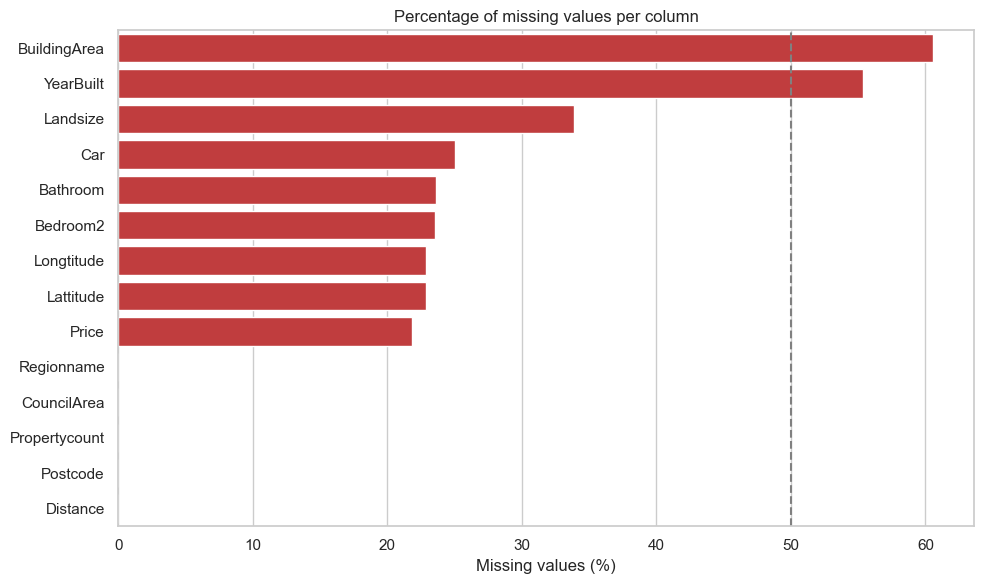

In [16]:
# Easy to understand this with a chart if there is any missing data.

fig, ax = plt.subplots(figsize=(10, 6))

# Only plot the columns that have at least one missing value
missing_to_plot = missing[missing["pct_missing"] > 0]

sns.barplot(data=missing_to_plot, x="pct_missing", y=missing_to_plot.index, color="tab:red", ax=ax)
ax.axvline(50, color="grey", linestyle="--")   # reference line at 50%
ax.set_title("Percentage of missing values per column")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("")
plt.tight_layout()
save_fig("01_missing_values")
plt.show()

# Can decide what columns to drop based on this analysis.

### 3.e. (i) Drop irrelevant and inconsistent columns and rows. 

In [17]:
# Drop BuildingArea (60.58% missing), Substituted with Landsize for further analysis.
df_clean = df_clean.drop(columns=["BuildingArea"])
df_clean.shape  # should now show 20 columns

(34857, 20)

In [18]:
# Drop rows where Price is missing
print("Missing Price before:", df_clean["Price"].isna().sum())
print("Rows before:", len(df_clean))

df_clean = df_clean.dropna(subset=["Price"])

print("Missing Price after:", df_clean["Price"].isna().sum())
print("Rows after:", len(df_clean))


Missing Price before: 7610
Rows before: 34857
Missing Price after: 0
Rows after: 27247


df_clean now has 27,247 rows and 20 columns
Figure saved to figures\02_missing_values_after_cleaning.png


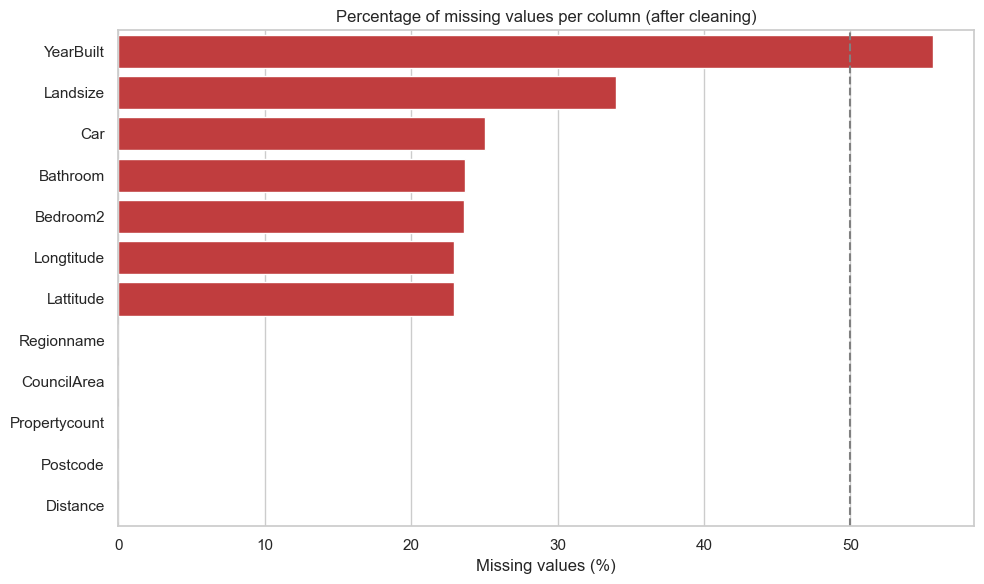

,n_missing,pct_missing
YearBuilt,15163,55.65
Landsize,9265,34.00
Car,6824,25.04
Bathroom,6447,23.66
Bedroom2,6441,23.64
Longtitude,6254,22.95
Lattitude,6254,22.95
Regionname,3,0.01
CouncilArea,3,0.01
Propertycount,3,0.01


In [19]:
# Missing values AFTER removing BuildingArea and rows with missing Price.
# Recalculate the report from df_clean so the chart shows the data as it is now.
missing_after = missing_report(df_clean)
print(f"df_clean now has {df_clean.shape[0]:,} rows and {df_clean.shape[1]} columns")

# Only plot the columns that still have at least one missing value
missing_after_to_plot = missing_after[missing_after["pct_missing"] > 0]

if missing_after_to_plot.empty:
    print("No missing values left in df_clean.")
else:
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.barplot(data=missing_after_to_plot, x="pct_missing", y=missing_after_to_plot.index, color="tab:red", ax=ax)
    ax.axvline(50, color="grey", linestyle="--")   # reference line at 50%
    ax.set_title("Percentage of missing values per column (after cleaning)")
    ax.set_xlabel("Missing values (%)")
    ax.set_ylabel("")
    plt.tight_layout()
    save_fig("02_missing_values_after_cleaning")
    plt.show()

missing_after_to_plot


In [20]:
# Drop rows where YearBuilt is missing
print("Missing YearBuilt before:", df_clean["YearBuilt"].isna().sum())
print("Rows before:", len(df_clean))

df_clean = df_clean.dropna(subset=["YearBuilt"])

print("Missing YearBuilt after:", df_clean["YearBuilt"].isna().sum())
print("Rows after:", len(df_clean))


Missing YearBuilt before: 15163
Rows before: 27247
Missing YearBuilt after: 0
Rows after: 12084


df_clean now has 12,084 rows and 20 columns
Figure saved to figures\03_missing_values_all_columns.png


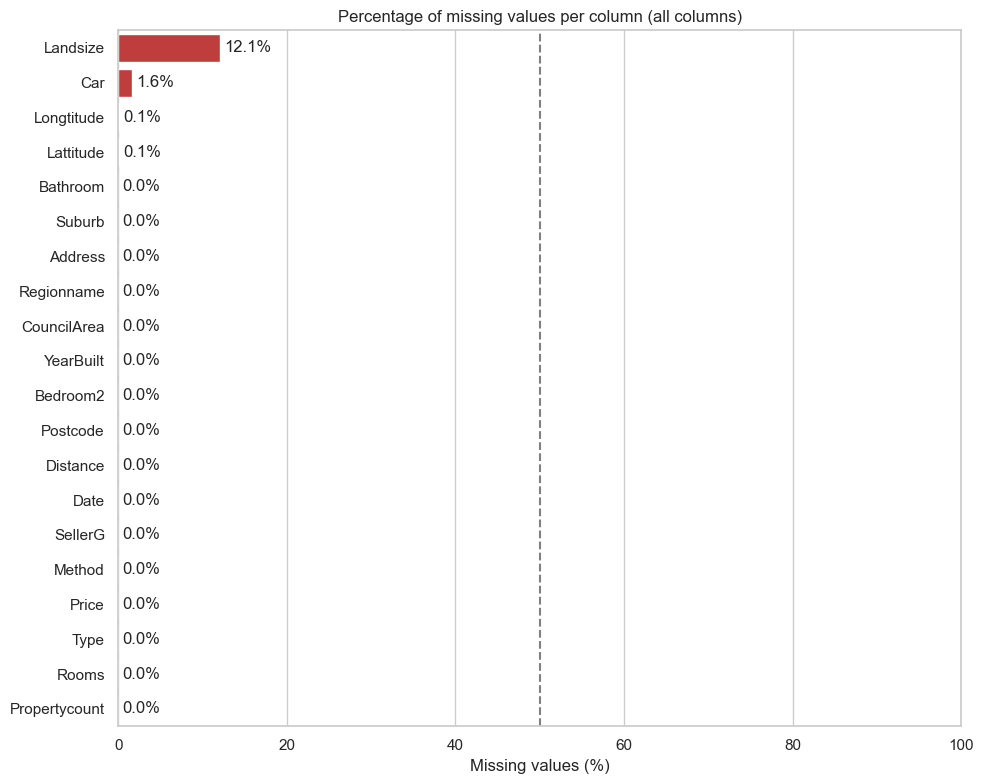

,n_missing,pct_missing
Landsize,1463,12.11
Car,196,1.62
Longtitude,8,0.07
Lattitude,8,0.07
Bathroom,1,0.01
Suburb,0,0.00
Address,0,0.00
Regionname,0,0.00
CouncilArea,0,0.00
YearBuilt,0,0.00


In [21]:
# Missing values for ALL columns (including those with 0 missing)
missing_all = missing_report(df_clean)
print(f"df_clean now has {df_clean.shape[0]:,} rows and {df_clean.shape[1]} columns")

fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(data=missing_all, x="pct_missing", y=missing_all.index, color="tab:red", ax=ax)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)   # show the % next to every bar, even 0
ax.axvline(50, color="grey", linestyle="--")   # reference line at 50%
ax.set_xlim(0, 100)                            # fixed scale so charts are easy to compare
ax.set_title("Percentage of missing values per column (all columns)")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("")
plt.tight_layout()
save_fig("03_missing_values_all_columns")
plt.show()

missing_all


### 3.e. (ii) Imputation done to fill missing data.

In [22]:
# Fill missing Car values with the median
print("Missing Car before:", df_clean["Car"].isna().sum())

car_median = df_clean["Car"].median()
df_clean["Car"] = df_clean["Car"].fillna(car_median)

print(f"Filled with median: {car_median}")
print("Missing Car after:", df_clean["Car"].isna().sum())


Missing Car before: 196
Filled with median: 2.0
Missing Car after: 0


### 3.f. (i) Fix inconsistent data types

Give the date format. 
1. Date is day/month/year. Plain pd.to_datetime() can read 3/09/2016 as March 9 instead of September 3, so the code passes format="%d/%m/%Y".
2. Use "Int64", not "int". Plain int fails if any NaN are left, for example in Bathroom or Bedroom2 if you haven't filled them yet. Int64 allows missing values.
3. Postcode becomes text so it isn't treated as a number. An average postcode means nothing.
4. Two column names are misspelled: Lattitude and Longtitude. They aren't data type problems, but you can fix them in step b, "Tidy column names":

In [23]:
# Fix inconsistent data types
print("--- Before ---")
print(df_clean.dtypes)

# 1. Date: text -> datetime. The dates are day/month/year (3/09/2016 = 3 Sep 2016).
df_clean["Date"] = pd.to_datetime(df_clean["Date"], format="%d/%m/%Y")

# 2. Postcode: a label, not a number to average -> string
df_clean["Postcode"] = df_clean["Postcode"].astype("Int64").astype("string")

# 3. Counts and years: float -> whole numbers.
#    "Int64" (capital I) still allows missing values, so it won't crash if any NaN are left.
int_cols = ["Car", "Bedroom2", "Bathroom", "YearBuilt", "Propertycount"]
df_clean[int_cols] = df_clean[int_cols].round().astype("Int64")

# 4. Repeated text labels -> category (uses less memory, useful for plotting/grouping)
cat_cols = ["Type", "Method", "Regionname", "CouncilArea"]
df_clean[cat_cols] = df_clean[cat_cols].astype("category")

print("\n--- After ---")
print(df_clean.dtypes)


--- Before ---
Suburb            object
Address           object
Rooms              int64
Type              object
Price            float64
Method            object
SellerG           object
Date              object
Distance         float64
Postcode         float64
Bedroom2         float64
Bathroom         float64
Car              float64
Landsize         float64
YearBuilt        float64
CouncilArea       object
Lattitude        float64
Longtitude       float64
Regionname        object
Propertycount    float64
dtype: object

--- After ---
Suburb                   object
Address                  object
Rooms                     int64
Type                   category
Price                   float64
Method                 category
SellerG                  object
Date             datetime64[ns]
Distance                float64
Postcode         string[python]
Bedroom2                  Int64
Bathroom                  Int64
Car                       Int64
Landsize                float64
YearBuil

In [24]:
df_clean = df_clean.rename(columns={"Lattitude": "Latitude", "Longtitude": "Longitude"})


In [25]:
# Check new dataset scope.

print(f"Reduced data scope: {len(df_clean)}")
df_clean.head()

Reduced data scope: 12084


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,YearBuilt,CouncilArea,Latitude,Longitude,Regionname,Propertycount
2,Abbotsford,25 Bloomburg St,2,h,"1,035,000.00",S,Biggin,2016-02-04,2.50,3067,2,1,0,156.00,1900,Yarra City Council,-37.81,144.99,Northern Metropolitan,4019
4,Abbotsford,5 Charles St,3,h,"1,465,000.00",SP,Biggin,2017-03-04,2.50,3067,3,2,0,134.00,1900,Yarra City Council,-37.81,144.99,Northern Metropolitan,4019
6,Abbotsford,55a Park St,4,h,"1,600,000.00",VB,Nelson,2016-06-04,2.50,3067,3,1,2,120.00,2014,Yarra City Council,-37.81,144.99,Northern Metropolitan,4019
11,Abbotsford,124 Yarra St,3,h,"1,876,000.00",S,Nelson,2016-05-07,2.50,3067,4,2,0,245.00,1910,Yarra City Council,-37.80,145.00,Northern Metropolitan,4019
14,Abbotsford,98 Charles St,2,h,"1,636,000.00",S,Nelson,2016-10-08,2.50,3067,2,1,2,256.00,1890,Yarra City Council,-37.81,145.00,Northern Metropolitan,4019


In [26]:
# check the info and data types of each column in the cleaned table
df_clean.info()
df_clean.describe(include="all").T

<class 'pandas.core.frame.DataFrame'>
Index: 12084 entries, 2 to 34856
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Suburb         12084 non-null  object        
 1   Address        12084 non-null  object        
 2   Rooms          12084 non-null  int64         
 3   Type           12084 non-null  category      
 4   Price          12084 non-null  float64       
 5   Method         12084 non-null  category      
 6   SellerG        12084 non-null  object        
 7   Date           12084 non-null  datetime64[ns]
 8   Distance       12084 non-null  float64       
 9   Postcode       12084 non-null  string        
 10  Bedroom2       12084 non-null  Int64         
 11  Bathroom       12083 non-null  Int64         
 12  Car            12084 non-null  Int64         
 13  Landsize       10621 non-null  float64       
 14  YearBuilt      12084 non-null  Int64         
 15  CouncilArea    12084 non

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Suburb,12084,324,Reservoir,260,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Address,12084,11909,25 William St,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rooms,"12,084.00",NaN,NaN,NaN,3.06,1.00,2.00,3.00,4.00,12.00,0.97
Type,12084,3,h,8736,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,"12,084.00",NaN,NaN,NaN,"1,077,201.64","85,000.00","632,000.00","885,000.00","1,320,000.00","9,000,000.00","671,327.71"
Method,12084,5,S,7655,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SellerG,12084,278,Nelson,1266,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,12084,NaN,NaN,NaN,2017-04-28 09:48:19.304866048,2016-02-04 00:00:00,2016-10-15 00:00:00,2017-06-17 00:00:00,2017-10-07 00:00:00,2018-03-17 00:00:00,NaN
Distance,"12,084.00",NaN,NaN,NaN,11.29,0.00,6.40,10.30,14.00,48.10,6.97
Postcode,12084,199,3073,260,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 3.f. (ii) Fix outliers

Figure saved to figures\04_boxplots_before_outliers.png


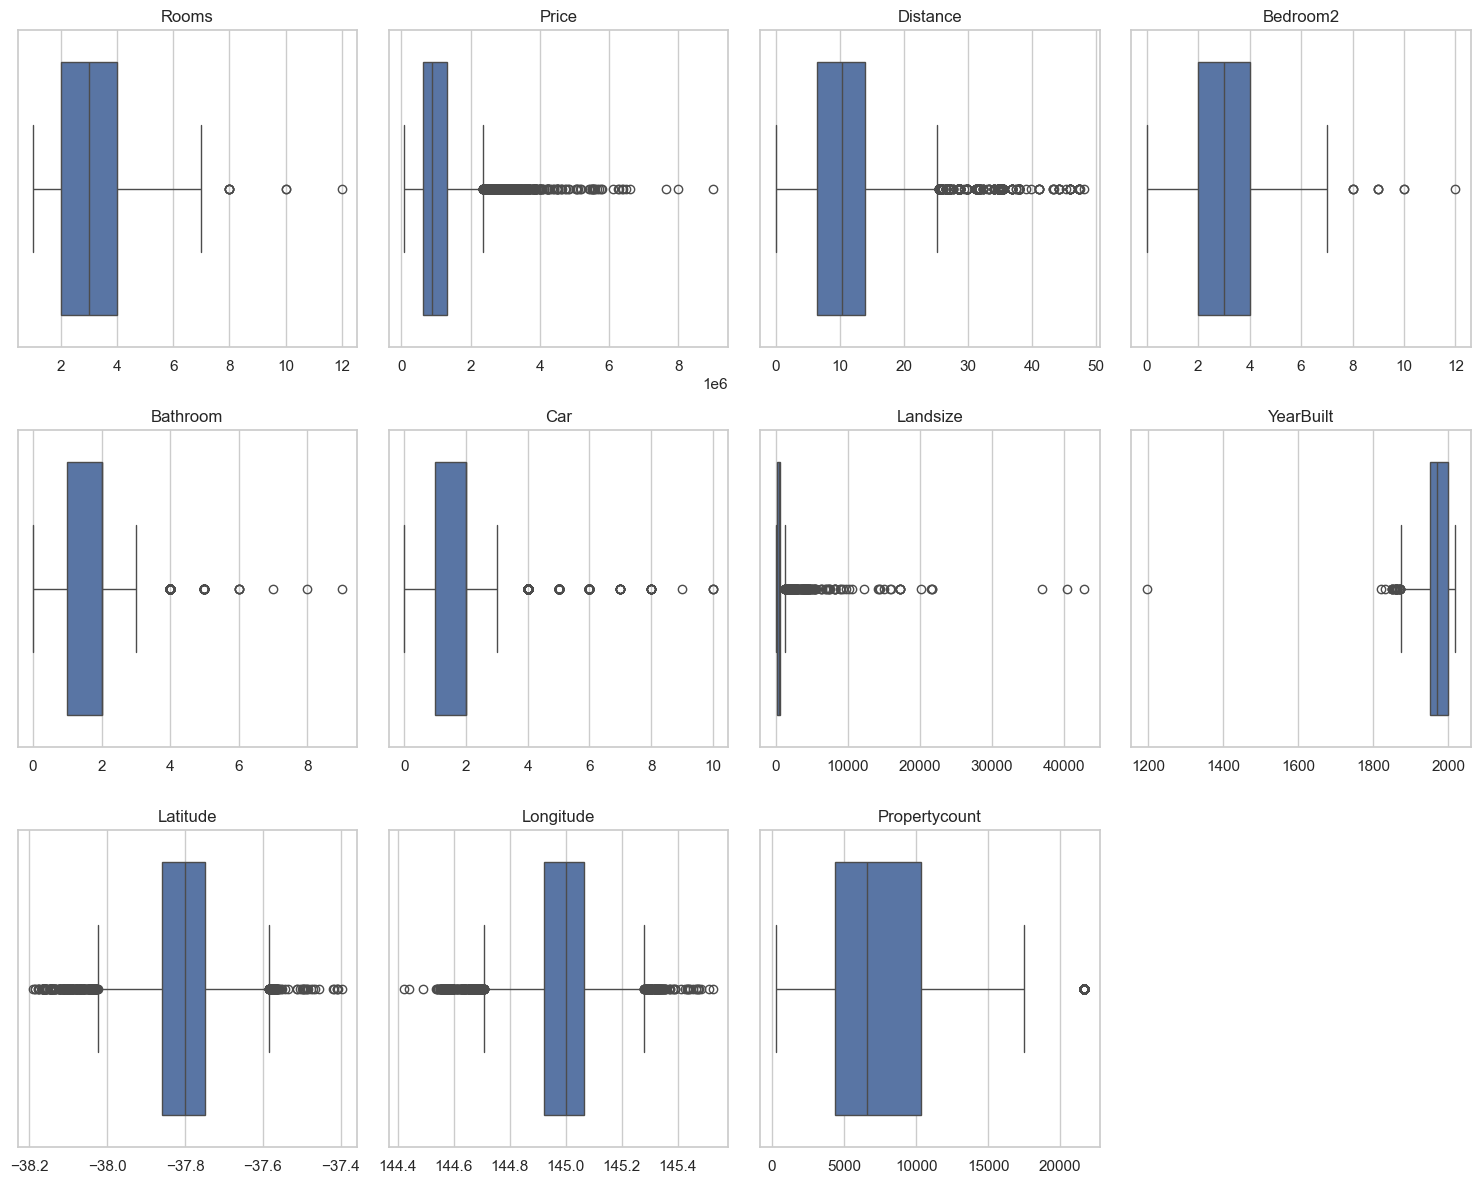

In [27]:
# Inspect the distribution of the numeric columns using boxplots to identify outliers.

# Box -> Middle 50% of values
# Line inside the box -> Median, the middle value
# Whiskers -> Range defined by the boxplot rule (1.5 x IQR)
# Dots beyond the whiskers -> Potential outliers to investigate

def plot_boxplots(data, name):
    num_cols = data.select_dtypes(include="number").columns.tolist()
    n_rows = int(np.ceil(len(num_cols) / 4))

    fig, axes = plt.subplots(n_rows, 4, figsize=(15, 4 * n_rows))
    axes = axes.flatten()

    for i, col in enumerate(num_cols):
        sns.boxplot(x=data[col].astype(float), ax=axes[i])
        axes[i].set_title(col)
        axes[i].set_xlabel("")

    # Turn off the empty axes in the last row
    for j in range(len(num_cols), len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    save_fig(name)
    plt.show()

plot_boxplots(df_clean, "04_boxplots_before_outliers")


In [28]:
# Fix outliers
rows_before = len(df_clean)

# 1. Remove impossible / unrealistic values (rules based on what a house can be).
#    Missing values are kept (they are handled by imputation, not here).
rules = {
    "Rooms":     (1, 10),
    "Bedroom2":  (0, 10),
    "Bathroom":  (1, 8),
    "Car":       (0, 10),
    "YearBuilt": (1800, 2018),   # sales are from 2016-2017, nothing built in the future
}

for col, (low, high) in rules.items():
    keep = (df_clean[col].isna() | df_clean[col].between(low, high)).astype(bool)
    print(f"{col}: removing {(~keep).sum()} rows outside {low}-{high}")
    df_clean = df_clean[keep]

# 2. Landsize: 0 is valid (apartments), but a few huge values (up to 433,014 m²) stretch the data.
#    Cap them at the 99th percentile instead of deleting the rows.
landsize_cap = df_clean["Landsize"].quantile(0.99)
n_capped = (df_clean["Landsize"] > landsize_cap).sum()
df_clean["Landsize"] = df_clean["Landsize"].clip(upper=landsize_cap)
print(f"Landsize: capped {n_capped} values at {landsize_cap:,.0f} m²")

print(f"\nRows before: {rows_before:,} | Rows after: {len(df_clean):,} | Removed: {rows_before - len(df_clean):,}")


Rooms: removing 1 rows outside 1-10
Bedroom2: removing 0 rows outside 0-10
Bathroom: removing 3 rows outside 1-8
Car: removing 0 rows outside 0-10
YearBuilt: removing 2 rows outside 1800-2018
Landsize: capped 107 values at 2,841 m²

Rows before: 12,084 | Rows after: 12,078 | Removed: 6


Figure saved to figures\05_boxplots_after_outliers.png


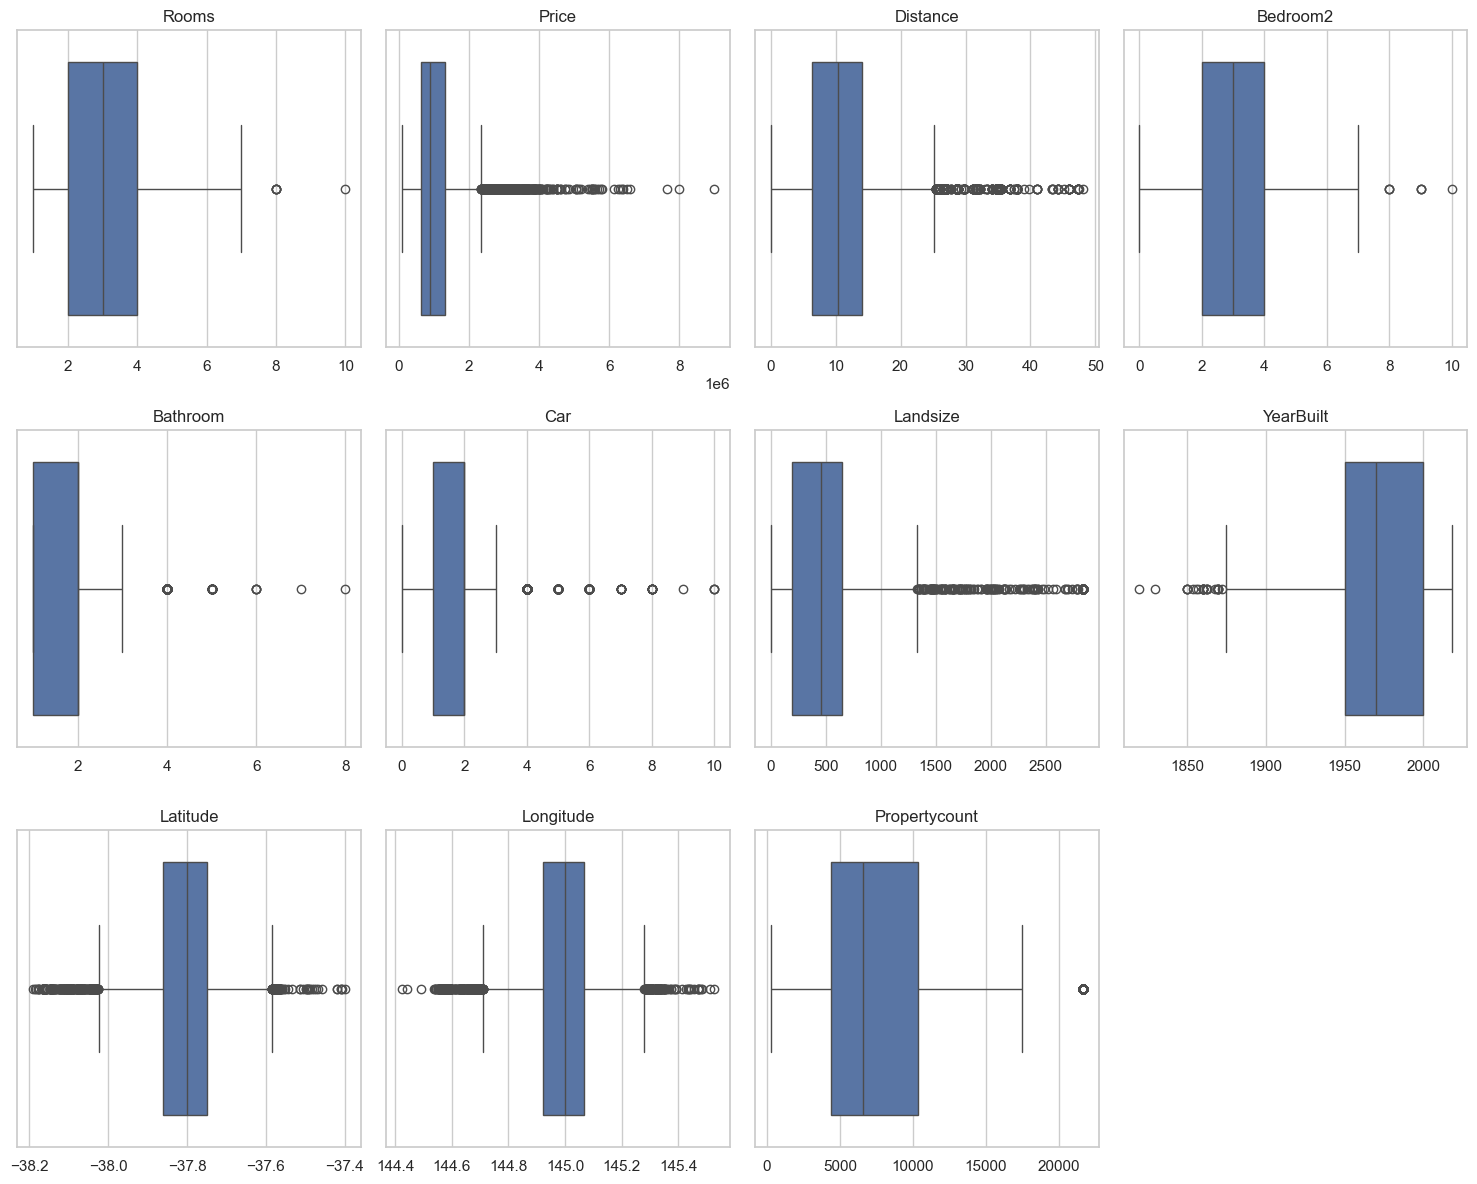

In [29]:
plot_boxplots(df_clean, "05_boxplots_after_outliers")


In [30]:
# This block loops through selected quantitative fields and caps outliers (IQR method)

# Only cap feature columns where extreme values distort the data.
# NOT capped:
#   - Price: the target; expensive houses are real sales
#   - Lattitude / Longtitude: locations, not measurements
#   - Propertycount: number of properties in the suburb, not a property feature
#   - YearBuilt: already cleaned with a 1800-2018 rule; old houses are real
cols_to_cap = ["Rooms", "Distance", "Bedroom2", "Bathroom", "Car", "Landsize"]

# Keep only the columns that exist in df_clean (in case one was dropped earlier)
cols_to_cap = [col for col in cols_to_cap if col in df_clean.columns]

# Loop through each column and cap outliers
for col in cols_to_cap:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Whole-number columns (Int64) can't hold decimals, so round the bounds outward
    if pd.api.types.is_integer_dtype(df_clean[col]):
        lower_bound = int(np.floor(lower_bound))
        upper_bound = int(np.ceil(upper_bound))

    # Count how many values will be changed
    n_capped = ((df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)).sum()

    # Print the calculated boundaries for transparency
    print(f"Column '{col}' Bounds -> Lower: {lower_bound:.2f}, Upper: {upper_bound:.2f} | Capped: {n_capped}")

    # Cap values outside the bounds
    df_clean[col] = df_clean[col].clip(lower=lower_bound, upper=upper_bound)

# Check the result
print(df_clean[cols_to_cap].describe().T)
df_clean.head(10)


Column 'Rooms' Bounds -> Lower: -1.00, Upper: 7.00 | Capped: 6
Column 'Distance' Bounds -> Lower: -5.00, Upper: 25.40 | Capped: 571
Column 'Bedroom2' Bounds -> Lower: -1.00, Upper: 7.00 | Capped: 7
Column 'Bathroom' Bounds -> Lower: -1.00, Upper: 4.00 | Capped: 36
Column 'Car' Bounds -> Lower: -1.00, Upper: 4.00 | Capped: 150
Column 'Landsize' Bounds -> Lower: -484.00, Upper: 1332.00 | Capped: 270
             count   mean    std  min    25%    50%    75%      max
Rooms    12,078.00   3.06   0.96 1.00   2.00   3.00   4.00     7.00
Distance 12,078.00  10.97   6.02 0.00   6.40  10.30  14.00    25.40
Bedroom2 12,078.00   3.05   0.96 0.00   2.00   3.00   4.00     7.00
Bathroom 12,077.00   1.63   0.69 1.00   1.00   2.00   2.00     4.00
Car      12,078.00   1.67   0.87 0.00   1.00   2.00   2.00     4.00
Landsize 10,615.00 450.33 310.32 0.00 197.00 460.00 651.00 1,332.00


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,YearBuilt,CouncilArea,Latitude,Longitude,Regionname,Propertycount
2,Abbotsford,25 Bloomburg St,2,h,"1,035,000.00",S,Biggin,2016-02-04,2.50,3067,2,1,0,156.00,1900,Yarra City Council,-37.81,144.99,Northern Metropolitan,4019
4,Abbotsford,5 Charles St,3,h,"1,465,000.00",SP,Biggin,2017-03-04,2.50,3067,3,2,0,134.00,1900,Yarra City Council,-37.81,144.99,Northern Metropolitan,4019
6,Abbotsford,55a Park St,4,h,"1,600,000.00",VB,Nelson,2016-06-04,2.50,3067,3,1,2,120.00,2014,Yarra City Council,-37.81,144.99,Northern Metropolitan,4019
11,Abbotsford,124 Yarra St,3,h,"1,876,000.00",S,Nelson,2016-05-07,2.50,3067,4,2,0,245.00,1910,Yarra City Council,-37.80,145.00,Northern Metropolitan,4019
14,Abbotsford,98 Charles St,2,h,"1,636,000.00",S,Nelson,2016-10-08,2.50,3067,2,1,2,256.00,1890,Yarra City Council,-37.81,145.00,Northern Metropolitan,4019
18,Abbotsford,10 Valiant St,2,h,"1,097,000.00",S,Biggin,2016-10-08,2.50,3067,3,1,2,220.00,1900,Yarra City Council,-37.80,145.00,Northern Metropolitan,4019
24,Abbotsford,40 Nicholson St,3,h,"1,350,000.00",VB,Nelson,2016-11-12,2.50,3067,3,2,2,214.00,2005,Yarra City Council,-37.81,145.00,Northern Metropolitan,4019
25,Abbotsford,123/56 Nicholson St,2,u,"750,000.00",S,Biggin,2016-11-12,2.50,3067,2,2,1,0.00,2009,Yarra City Council,-37.81,145.00,Northern Metropolitan,4019
30,Abbotsford,16 William St,2,h,"1,310,000.00",S,Jellis,2016-10-15,2.50,3067,2,1,2,238.00,1890,Yarra City Council,-37.81,145.00,Northern Metropolitan,4019
32,Abbotsford,42 Henry St,3,h,"1,200,000.00",S,Jellis,2016-07-16,2.50,3067,3,2,1,113.00,1880,Yarra City Council,-37.81,144.99,Northern Metropolitan,4019


Figure saved to figures\06_boxplots_affected_columns.png


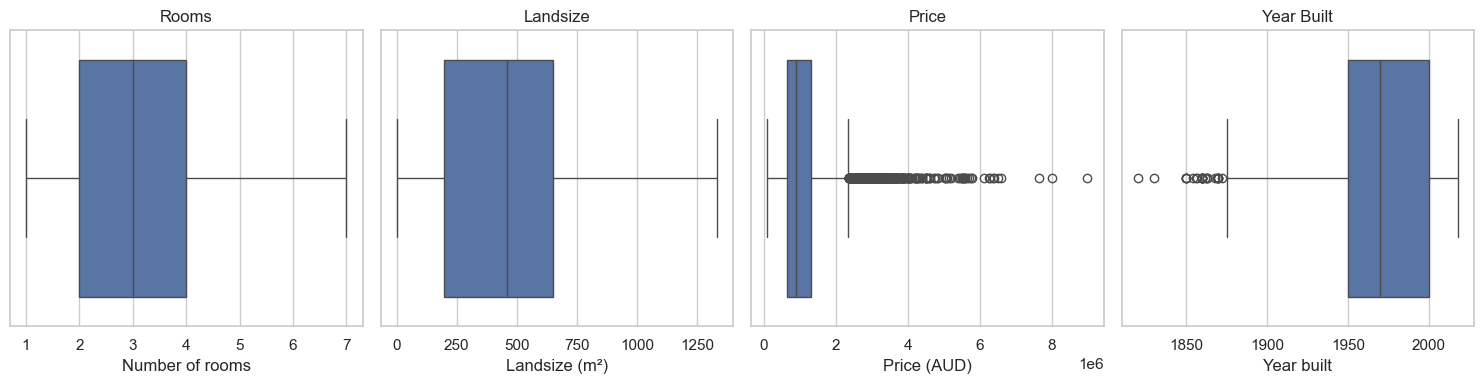

In [31]:
# Re-creating the box plots as before to demonstrate outlier capping:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

# 1. Rooms
sns.boxplot(x=df_clean["Rooms"].astype(float), ax=axes[0])
axes[0].set_title("Rooms")
axes[0].set_xlabel("Number of rooms")

# 2. Landsize
sns.boxplot(x=df_clean["Landsize"].astype(float), ax=axes[1])
axes[1].set_title("Landsize")
axes[1].set_xlabel("Landsize (m²)")

# 3. Price
sns.boxplot(x=df_clean["Price"].astype(float), ax=axes[2])
axes[2].set_title("Price")
axes[2].set_xlabel("Price (AUD)")

# 4. YearBuilt
sns.boxplot(x=df_clean["YearBuilt"].astype(float), ax=axes[3])
axes[3].set_title("Year Built")
axes[3].set_xlabel("Year built")

plt.tight_layout()
save_fig("06_boxplots_affected_columns")
plt.show()


In [32]:
# Initiating missing value analysis
missing_report(df_clean).head(12)

,n_missing,pct_missing
Landsize,1463,12.11
Longitude,8,0.07
Latitude,8,0.07
Bathroom,1,0.01
Suburb,0,0.00
Address,0,0.00
Regionname,0,0.00
CouncilArea,0,0.00
YearBuilt,0,0.00
Car,0,0.00


# 4. **Feature Engineering**     
Steps:     
    a. Extract **temporal features** (If necessary)  
    b. **Create** more features depending on the **relation between existing features**.              
    c. Format or transform variables to ensure they are fully model-ready 

In [33]:
# Feature Engineering
# 4.a. Temporal Features: Extract sale year and month from Date
#    (Date is day/month/year; if it is already datetime this line just keeps it as is)
df_clean["Date"] = pd.to_datetime(df_clean["Date"], format="%d/%m/%Y")
df_clean["SaleYear"] = df_clean["Date"].dt.year
df_clean["SaleMonth"] = df_clean["Date"].dt.month

# Age of the house at the moment it was sold
df_clean["HouseAge"] = df_clean["SaleYear"] - df_clean["YearBuilt"]

# 4.b. Property Ratios & Indicators:
# How much land each room has (spacious vs. compact properties)
df_clean["LandPerRoom"] = df_clean["Landsize"] / df_clean["Rooms"]

# Bathrooms relative to rooms (higher = more comfortable / higher-end property)
df_clean["BathPerRoom"] = df_clean["Bathroom"] / df_clean["Rooms"]

# Does the property have at least one car space? (1 = yes, 0 = no)
df_clean["HasCarSpace"] = (df_clean["Car"] > 0).astype("Int64")

# Is the property a house (h) rather than a unit (u) or townhouse (t)? (1 = yes, 0 = no)
df_clean["IsHouse"] = (df_clean["Type"] == "h").astype(int)

# 4.c. Location Feature:
# Group distance to the CBD into zones
df_clean["DistanceZone"] = pd.cut(
    df_clean["Distance"],
    bins=[-0.1, 5, 15, df_clean["Distance"].max()],
    labels=["Inner (0-5 km)", "Middle (5-15 km)", "Outer (15+ km)"]
)

# Display the first few rows with the newly created features
display(df_clean[["Suburb", "SaleYear", "SaleMonth", "HouseAge", "LandPerRoom",
                  "BathPerRoom", "HasCarSpace", "IsHouse", "DistanceZone"]].head())


,Suburb,SaleYear,SaleMonth,HouseAge,LandPerRoom,BathPerRoom,HasCarSpace,IsHouse,DistanceZone
2,Abbotsford,2016,2,116,78.00,0.50,0,1,Inner (0-5 km)
4,Abbotsford,2017,3,117,44.67,0.67,0,1,Inner (0-5 km)
6,Abbotsford,2016,6,2,30.00,0.25,1,1,Inner (0-5 km)
11,Abbotsford,2016,5,106,81.67,0.67,0,1,Inner (0-5 km)
14,Abbotsford,2016,10,126,128.00,0.50,1,1,Inner (0-5 km)


# 5. Comparing raw and clean datasets

In [34]:
# Before / after comparison
comparison = pd.DataFrame(
    {
        "raw": [
            len(df),
            df.shape[1],
            df.select_dtypes("number").shape[1],
            df.isna().mean().mean() * 100,
            df.memory_usage(deep=True).sum() / 1e6,
        ],
        "clean": [
            len(df_clean),
            df_clean.shape[1],
            df_clean.select_dtypes("number").shape[1],
            df_clean.isna().mean().mean() * 100,
            df_clean.memory_usage(deep=True).sum() / 1e6,
        ],
    },
    index=["rows", "columns", "numeric columns", "average % missing", "memory (MB)"],
)
comparison

,raw,clean
rows,"34,857.00","12,078.00"
columns,21.00,28.00
numeric columns,13.00,18.00
average % missing,13.79,0.87
memory (MB),20.23,4.72


# 6. **(EDA)** 
Exploring the data with **descriptive statistics** and **visualizations** (matplotlib + seaborn).

Steps:      
    a. **Descriptive Analysis**:   
    b. **Univariate**: one variable at a time: numerical variables
    c. **Univariate**: one variable at a time  
    d. **Bivariate**: two variables together       
    e. **Multivariate**: several variables at once    
        - Correlation

## 6.a. Descriptive Statistics 

In [35]:
key_numeric = df_clean.select_dtypes(include="number").columns.tolist()
key_numeric

stats = df_clean[key_numeric].describe().T

stats["skewness"] = df_clean[key_numeric].skew()
stats

,count,mean,std,min,25%,50%,75%,max,skewness
Rooms,"12,078.00",3.06,0.96,1.00,2.00,3.00,4.00,7.00,0.20
Price,"12,078.00","1,077,092.20","671,384.25","85,000.00","632,000.00","885,000.00","1,320,000.00","9,000,000.00",2.41
Distance,"12,078.00",10.97,6.02,0.00,6.40,10.30,14.00,25.40,0.72
Bedroom2,"12,078.00",3.05,0.96,0.00,2.00,3.00,4.00,7.00,0.20
Bathroom,"12,077.00",1.63,0.69,1.00,1.00,2.00,2.00,4.00,0.87
Car,"12,078.00",1.67,0.87,0.00,1.00,2.00,2.00,4.00,0.63
Landsize,"10,615.00",450.33,310.32,0.00,197.00,460.00,651.00,"1,332.00",0.51
YearBuilt,"12,078.00","1,966.67",36.09,"1,820.00","1,950.00","1,970.00","2,000.00","2,018.00",-0.59
Latitude,"12,070.00",-37.81,0.09,-38.19,-37.86,-37.80,-37.75,-37.40,-0.30
Longitude,"12,070.00",144.99,0.12,144.42,144.92,145.00,145.07,145.53,-0.35


## 6.b. Univariate Analysis

Figure saved to figures\08_univariate_numeric.png


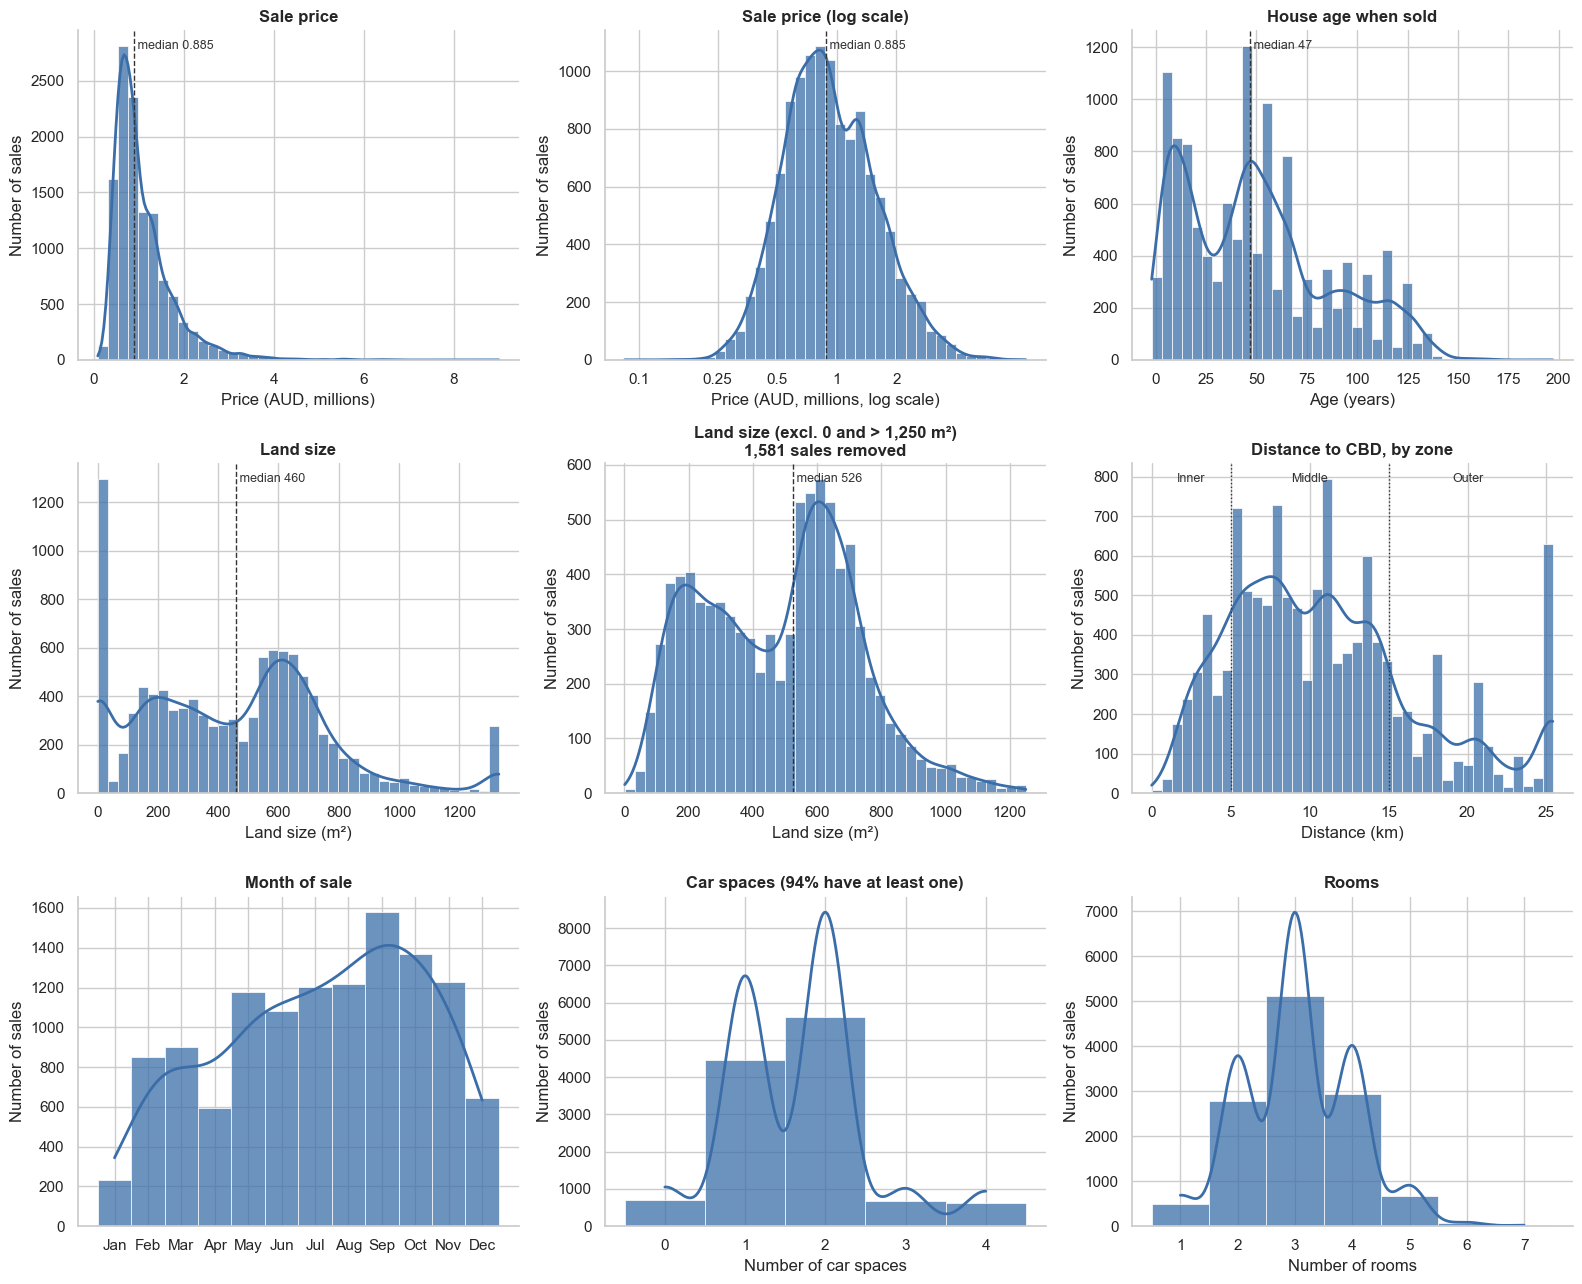

In [36]:
# Univariate Analysis (1/3): numeric columns -> histogram + KDE line
# Histogram   = how many sales fall in each range of values
# KDE line    = smoothed version of the histogram (the overall "shape" of the distribution)
# Dashed line = median (the middle value; not pulled around by very expensive houses)

BAR_COLOR = "#3b6ea8"   # one color for every chart: each plot shows a single variable
INK = "#333333"         # text and reference lines
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# Land size limits for the "trimmed" plot: 0 m² (mostly units) and the values near the cap pile up
LAND_MIN, LAND_MAX = 0, 1250

# (column, title, x-axis label, kind)
# kind = "continuous" -> normal histogram with 40 bins
#        "discrete"   -> one bar per whole number (months, car spaces, rooms)
#        "log"        -> logarithmic x-axis: spreads out cheap sales, squeezes the expensive tail
#        "trimmed"    -> extreme values removed before plotting
num_plots = [
    ("Price",     "Sale price",                      "Price (AUD, millions)",           "continuous"),
    ("Price",     "Sale price (log scale)",          "Price (AUD, millions, log scale)", "log"),
    ("HouseAge",  "House age when sold",             "Age (years)",                     "continuous"),
    ("Landsize",  "Land size",                       "Land size (m²)",                  "continuous"),
    ("Landsize",  f"Land size (excl. 0 and > {LAND_MAX:,} m²)", "Land size (m²)",       "trimmed"),
    ("Distance",  "Distance to CBD, by zone",        "Distance (km)",                   "continuous"),
    ("SaleMonth", "Month of sale",                   "",                                "discrete"),
    ("Car",       "Car spaces",                      "Number of car spaces",            "discrete"),
    ("Rooms",     "Rooms",                           "Number of rooms",                 "discrete"),
]

fig, axes = plt.subplots(3, 3, figsize=(16, 13))
axes = axes.flatten()
ax_by_col = {}   # remember which subplot shows which column (for the extra touches below)

for ax, (col, title, xlabel, kind) in zip(axes, num_plots):
    ax_by_col.setdefault(col, ax)
    values = df_clean[col].dropna().astype(float)
    if col == "Price":
        values = values / 1e6   # show millions so the axis is readable
    if kind == "trimmed":
        n_before = len(values)
        values = values[(values > LAND_MIN) & (values <= LAND_MAX)]
        title += f"\n{n_before - len(values):,} sales removed"

    discrete = kind == "discrete"
    sns.histplot(
        x=values, ax=ax, kde=True, discrete=discrete,
        bins="auto" if discrete else 40,
        log_scale=(kind == "log"),   # bins and KDE are computed on the log scale too
        color=BAR_COLOR, edgecolor="white", linewidth=0.5, alpha=0.75,
        kde_kws={"bw_adjust": 2 if discrete else 1},   # smoother line for whole-number columns
        line_kws={"linewidth": 2},
    )

    # Median reference line (skipped for whole-number columns, where it is just one of the bars)
    if not discrete and col != "Distance":
        median = values.median()
        ax.axvline(median, color=INK, linestyle="--", linewidth=1)
        ax.text(median, 0.97, f" median {median:,.3g}", transform=ax.get_xaxis_transform(),
                ha="left", va="top", fontsize=9, color=INK)

    # Log axis: readable price ticks instead of 10^-1, 10^0
    if kind == "log":
        ticks = [0.1, 0.25, 0.5, 1, 2]
        ax.set_xticks(ticks)
        ax.set_xticklabels([f"{t:g}" for t in ticks])
        ax.minorticks_off()

    ax.set_title(title, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Number of sales")

# Distance: mark the three zones used in the DistanceZone feature
ax = ax_by_col["Distance"]
for edge in [5, 15]:
    ax.axvline(edge, color=INK, linestyle=":", linewidth=1)
for x, label in [(2.5, "Inner"), (10, "Middle"), (20, "Outer")]:
    ax.text(x, 0.97, label, transform=ax.get_xaxis_transform(),
            ha="center", va="top", fontsize=9, color=INK)

# Month of sale: show month names instead of 1-12
ax_by_col["SaleMonth"].set_xticks(range(1, 13))
ax_by_col["SaleMonth"].set_xticklabels(MONTHS)

# Car spaces: add the share of properties with at least one space (HasCarSpace feature)
pct_car = df_clean["HasCarSpace"].mean() * 100
ax_by_col["Car"].set_title(f"Car spaces ({pct_car:.0f}% have at least one)", fontweight="bold")
ax_by_col["Car"].set_xticks(range(0, int(df_clean["Car"].max()) + 1))

# Note: Landsize was capped at its upper IQR bound and units often have 0 m²,
# so the full Land size plot has a spike at 0 and a pile-up at the right edge;
# the trimmed plot next to it shows the typical house lot without them.

sns.despine()
plt.tight_layout()
save_fig("08_univariate_numeric")
plt.show()

Figure saved to figures\09_univariate_categorical.png


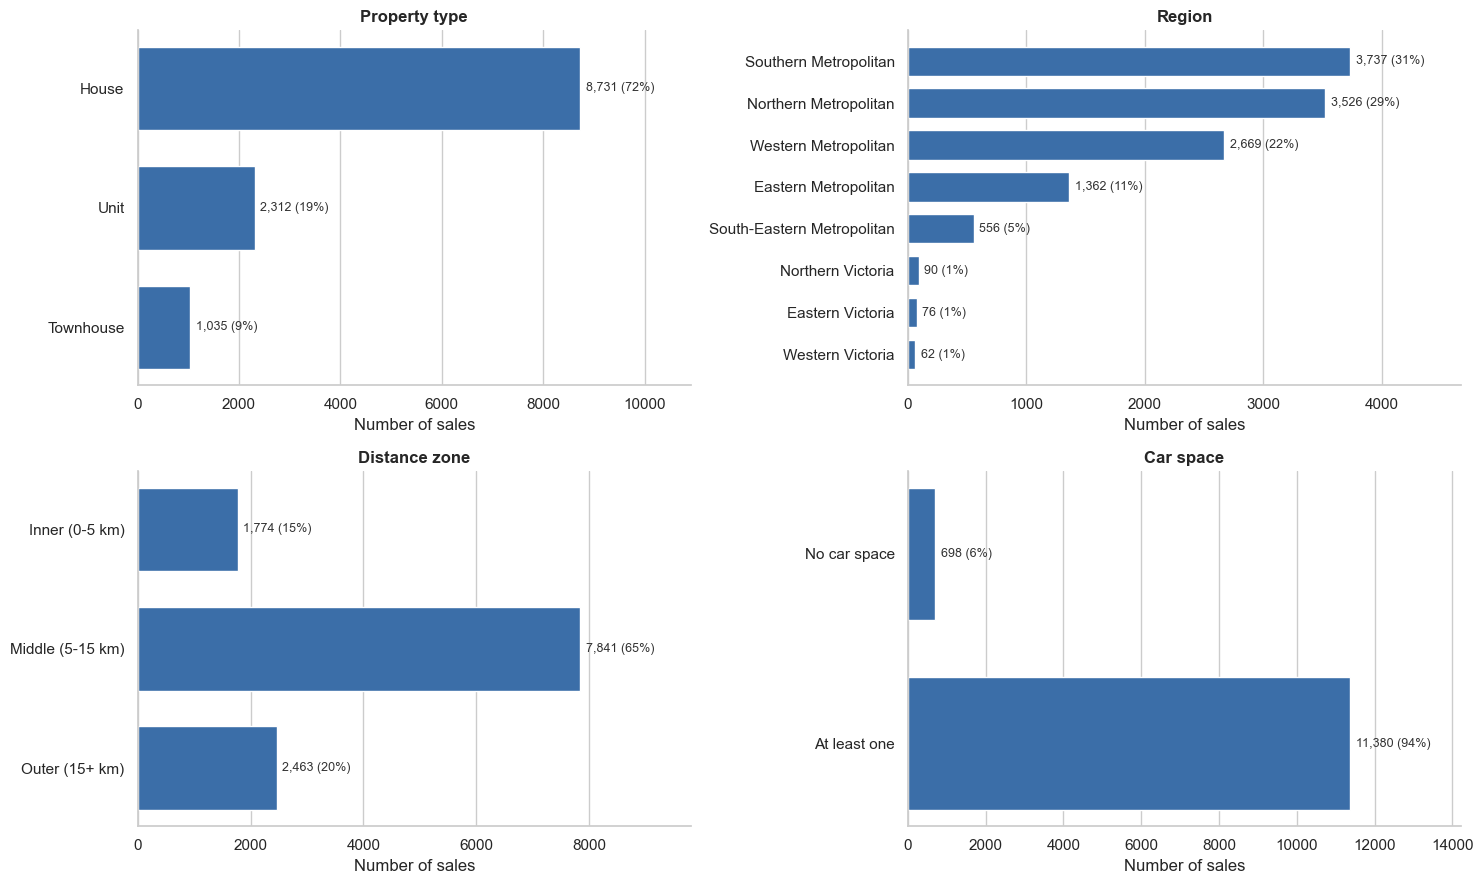

In [37]:
# Univariate Analysis (2/3): categorical columns -> bar chart with count and %
# A KDE line has no meaning for categories (there is nothing "between" House and Unit),
# so these stay as bar charts.

bar_color = "#3b6ea8"

# (column, title, nicer labels, sort by count?)
# DistanceZone and HasCarSpace keep their natural order (inner -> outer, no -> yes)
cat_plots = [
    ("Type",         "Property type", {"h": "House", "u": "Unit", "t": "Townhouse"}, True),
    ("Regionname",   "Region",        None,                                          True),
    ("DistanceZone", "Distance zone", None,                                          False),
    ("HasCarSpace",  "Car space",     {"0": "No car space", "1": "At least one"},    False),
]

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
axes = axes.flatten()

for ax, (col, title, labels, sort_by_count) in zip(axes, cat_plots):
    counts = df_clean[col].value_counts(sort=sort_by_count)
    if not sort_by_count:
        counts = counts.sort_index()
    counts.index = counts.index.astype(str)
    if labels:
        counts = counts.rename(index=labels)
    pct = counts / counts.sum() * 100

    ax.barh(counts.index, counts.values, color=bar_color, height=0.7)
    ax.invert_yaxis()   # first category on top
    ax.bar_label(ax.containers[0], labels=[f"{n:,} ({p:.0f}%)" for n, p in zip(counts, pct)],
                 padding=4, fontsize=9, color=INK)
    ax.set_xlim(0, counts.max() * 1.25)   # leave room for the labels
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Number of sales")
    ax.grid(axis="y", visible=False)

sns.despine()
plt.tight_layout()
save_fig("09_univariate_categorical")
plt.show()

Figure saved to figures\09_univariate_categorical_2.png


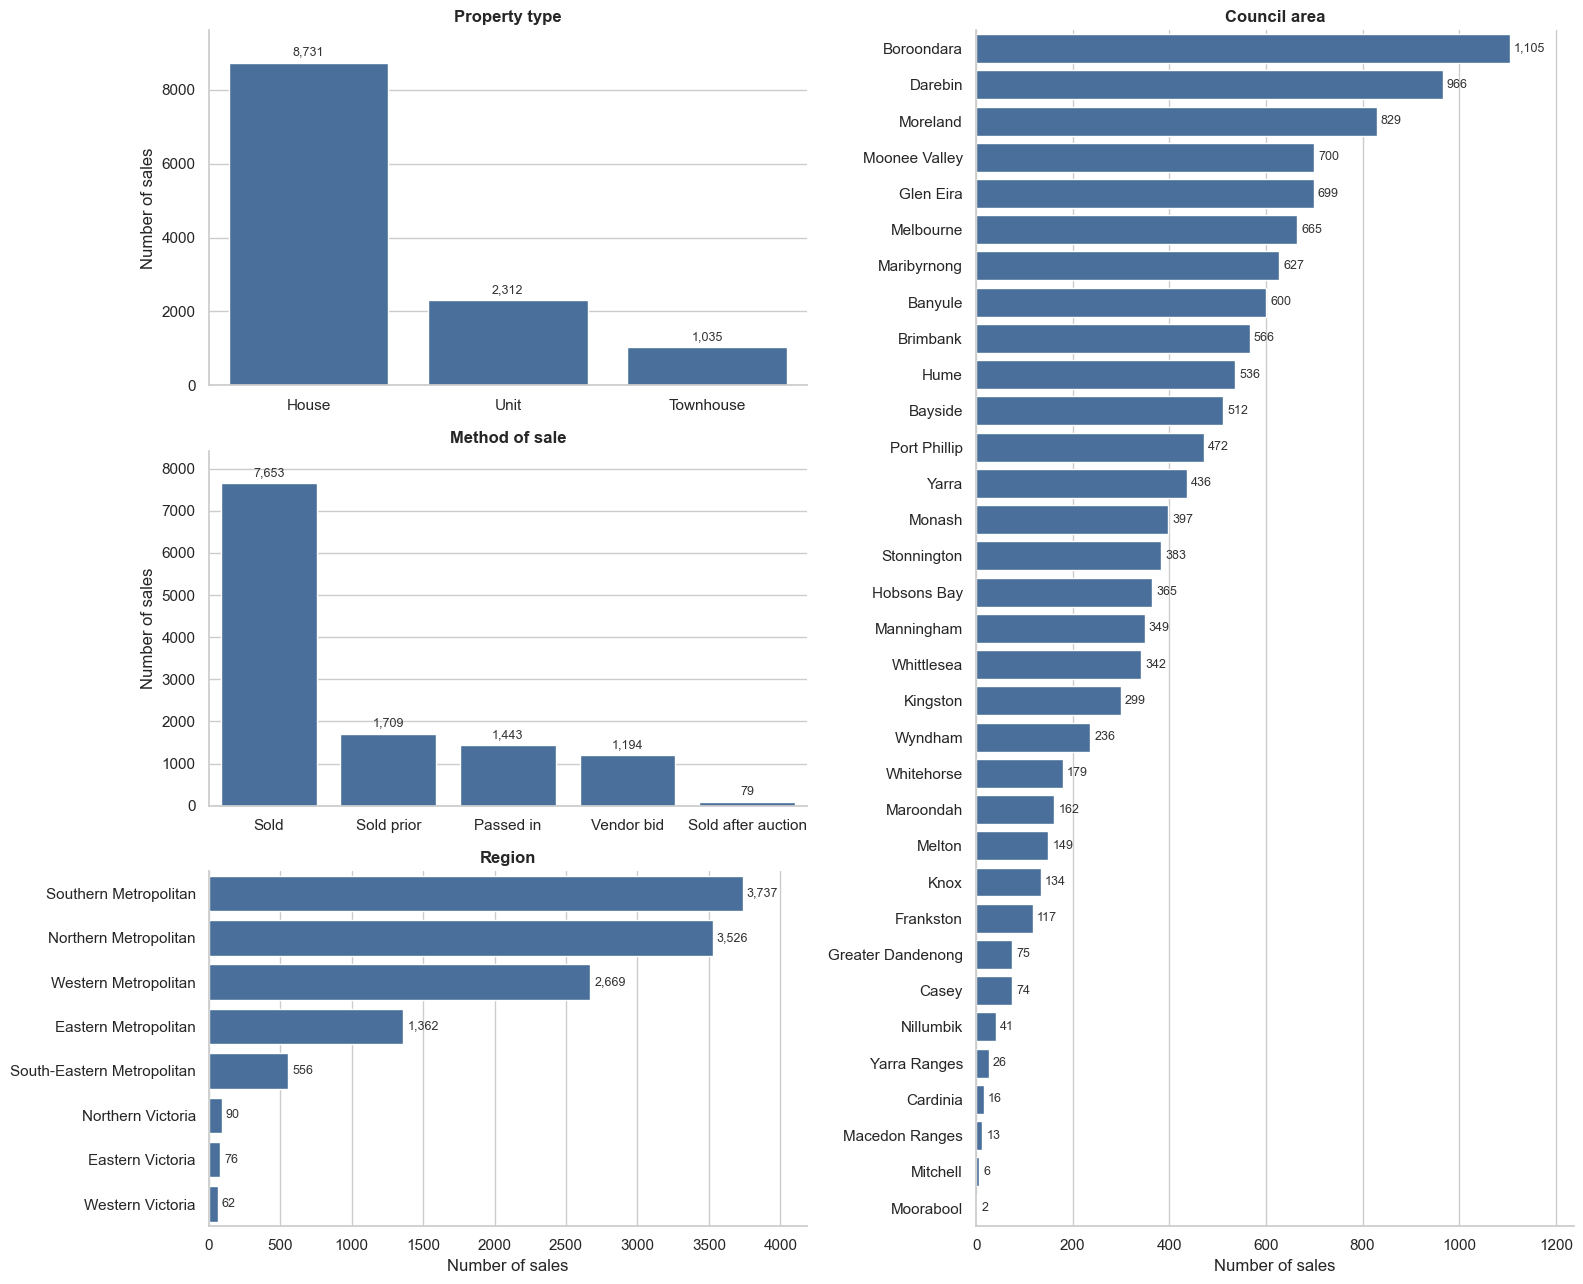

In [38]:
# Univariate Analysis (3/3): categorical columns -> count plots
# A KDE line has no meaning for categories (there is nothing "between" House and Unit),
# so these are bar charts: one bar per category, height = number of sales.

# Readable names for the short codes used in the dataset
type_names = {"h": "House", "u": "Unit", "t": "Townhouse"}
method_names = {"S": "Sold", "SP": "Sold prior", "PI": "Passed in",
                "VB": "Vendor bid", "SA": "Sold after auction"}

# .astype(str) drops unused categories, so no empty bars appear
type_label = df_clean["Type"].astype(str).map(type_names)
method_label = df_clean["Method"].astype(str).map(method_names)
region_label = df_clean["Regionname"].astype(str)
# "Boroondara City Council" -> "Boroondara" (shorter labels, same information)
council_label = df_clean["CouncilArea"].astype(str).str.replace(r" (City|Shire) Council$", "", regex=True)

# Layout: three small charts on the left, council area (33 bars) uses the whole right column
fig = plt.figure(figsize=(16, 13))
grid = fig.add_gridspec(3, 2)
ax_type = fig.add_subplot(grid[0, 0])
ax_method = fig.add_subplot(grid[1, 0])
ax_region = fig.add_subplot(grid[2, 0])
ax_council = fig.add_subplot(grid[:, 1])

# order=... sorts the bars from most to least frequent
sns.countplot(x=type_label, order=type_label.value_counts().index,
              color=BAR_COLOR, ax=ax_type)
ax_type.set_title("Property type", fontweight="bold")
ax_type.set_xlabel("")

sns.countplot(x=method_label, order=method_label.value_counts().index,
              color=BAR_COLOR, ax=ax_method)
ax_method.set_title("Method of sale", fontweight="bold")
ax_method.set_xlabel("")

# Region and council names are long, so these are horizontal (y=...)
sns.countplot(y=region_label, order=region_label.value_counts().index,
              color=BAR_COLOR, ax=ax_region)
ax_region.set_title("Region", fontweight="bold")

sns.countplot(y=council_label, order=council_label.value_counts().index,
              color=BAR_COLOR, ax=ax_council)
ax_council.set_title("Council area", fontweight="bold")

for ax in [ax_type, ax_method]:   # vertical bar charts
    ax.set_ylabel("Number of sales")
    ax.margins(y=0.1)             # room for the count labels above the bars
for ax in [ax_region, ax_council]:   # horizontal bar charts
    ax.set_xlabel("Number of sales")
    ax.set_ylabel("")
    ax.margins(x=0.12)               # room for the count labels after the bars
for ax in [ax_type, ax_method, ax_region, ax_council]:
    ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3, fontsize=9, color=INK)   # count on each bar

sns.despine()
plt.tight_layout()
save_fig("09_univariate_categorical_2")
plt.show()


## 6.c. Bivariate Analysis

Figure saved to figures\10_bivariate_price_by_suburb.png


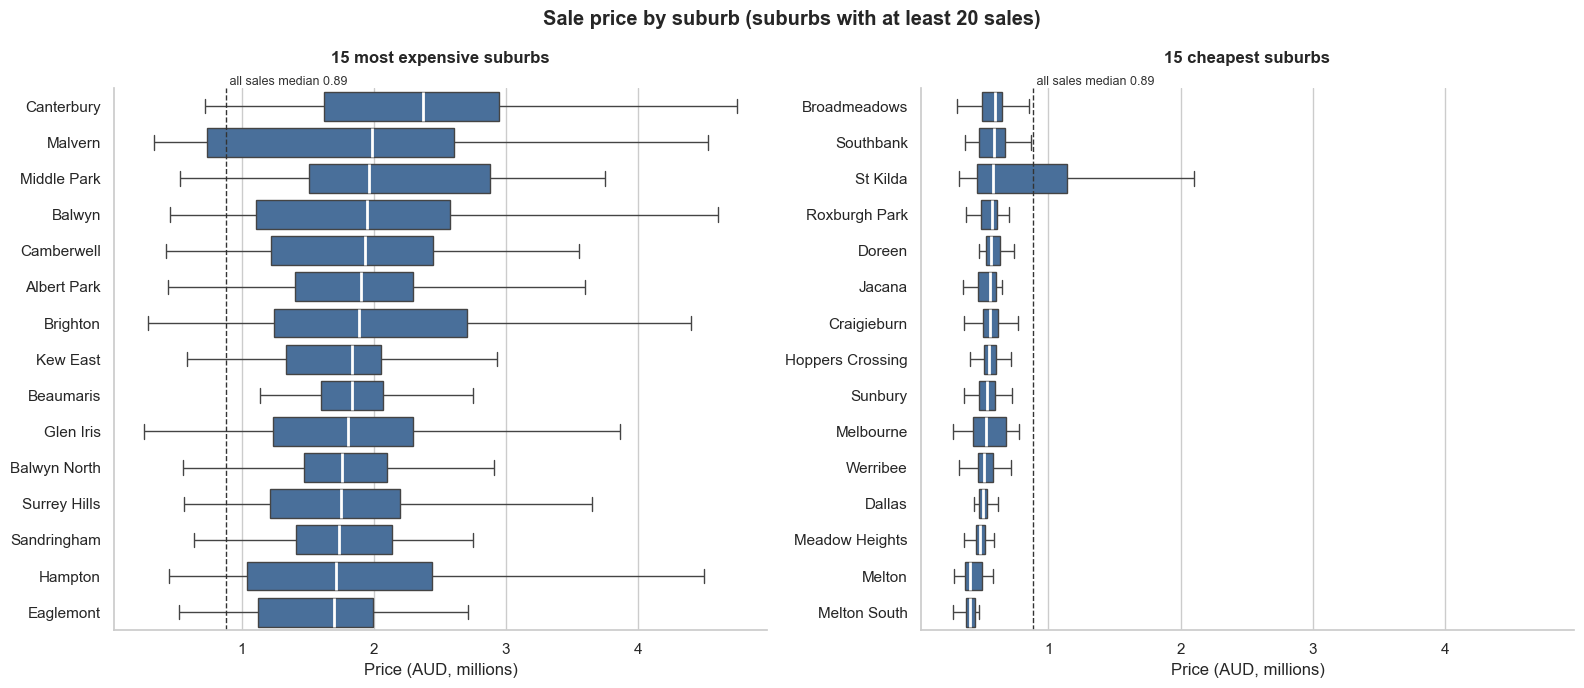

In [39]:
# Bivariate Analysis (1/4): Price by suburb
# Box   = middle 50% of sale prices in that suburb
# White line inside the box = median price
# Dashed line = median price of ALL sales (to compare each suburb against Melbourne overall)
#
# There are 300+ suburbs, too many for one chart, so we compare the 15 most expensive with
# the 15 cheapest (by median). Suburbs with fewer than 20 sales are left out: a median from
# a handful of sales is not reliable.

MIN_SALES = 20
TOP_N = 15

biv = df_clean.assign(PriceM=df_clean["Price"] / 1e6)   # price in millions, as in the univariate plots
price_median_all = biv["PriceM"].median()

def box_by_group(data, x, y, order, ax, overall=None, overall_label=""):
    # Horizontal boxplot of x for each group in y, in the given order (outlier dots hidden)
    sns.boxplot(data=data, x=x, y=y, order=order, color=BAR_COLOR, showfliers=False,
                medianprops={"color": "white", "linewidth": 2}, ax=ax)
    if overall is not None:
        ax.axvline(overall, color=INK, linestyle="--", linewidth=1)
        ax.text(overall, 1.0, f" {overall_label}", transform=ax.get_xaxis_transform(),
                ha="left", va="bottom", fontsize=9, color=INK)
    ax.set_ylabel("")

def highest_and_lowest(value_col):
    # Suburbs with enough sales, ranked by median value_col -> (data, top names, bottom names)
    counts = biv["Suburb"].value_counts()
    data = biv[biv["Suburb"].isin(counts[counts >= MIN_SALES].index)]
    ranked = data.groupby("Suburb")[value_col].median().sort_values(ascending=False)
    return data, ranked.index[:TOP_N], ranked.index[-TOP_N:]

suburb_data, priciest, cheapest = highest_and_lowest("PriceM")

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharex=True)
for ax, names, title in [(axes[0], priciest, f"{TOP_N} most expensive suburbs"),
                         (axes[1], cheapest, f"{TOP_N} cheapest suburbs")]:
    box_by_group(suburb_data, "PriceM", "Suburb", names, ax,
                 overall=price_median_all, overall_label=f"all sales median {price_median_all:.2f}")
    ax.set_title(title, fontweight="bold", pad=18)
    ax.set_xlabel("Price (AUD, millions)")

fig.suptitle(f"Sale price by suburb (suburbs with at least {MIN_SALES} sales)", fontweight="bold")
sns.despine()
plt.tight_layout()
save_fig("10_bivariate_price_by_suburb")
plt.show()


Figure saved to figures\11_bivariate_price_by_council.png


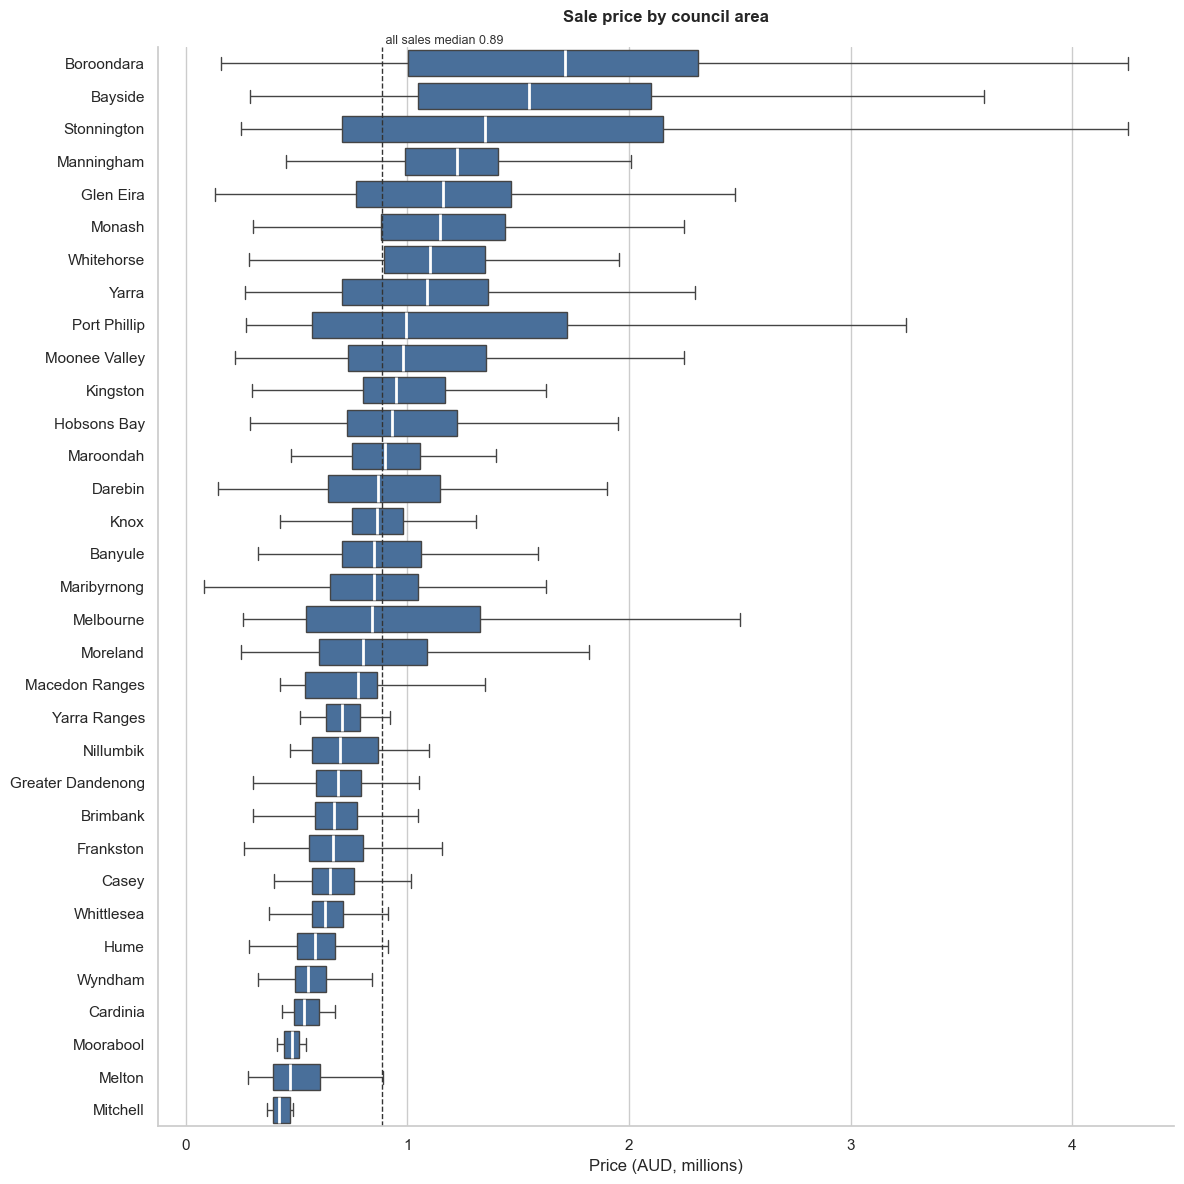

In [40]:
# Bivariate Analysis (2/4): Price by council area
# Same boxplot as for suburbs; all 33 council areas fit, sorted from most to least expensive.

# "Boroondara City Council" -> "Boroondara" (shorter labels, same information)
biv["Council"] = biv["CouncilArea"].astype(str).str.replace(r" (City|Shire) Council$", "", regex=True)
council_order = biv.groupby("Council")["PriceM"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(12, 12))
box_by_group(biv, "PriceM", "Council", council_order, ax,
             overall=price_median_all, overall_label=f"all sales median {price_median_all:.2f}")
ax.set_title("Sale price by council area", fontweight="bold", pad=18)
ax.set_xlabel("Price (AUD, millions)")

sns.despine()
plt.tight_layout()
save_fig("11_bivariate_price_by_council")
plt.show()


Figure saved to figures\12_bivariate_price_vs_land_and_rooms.png


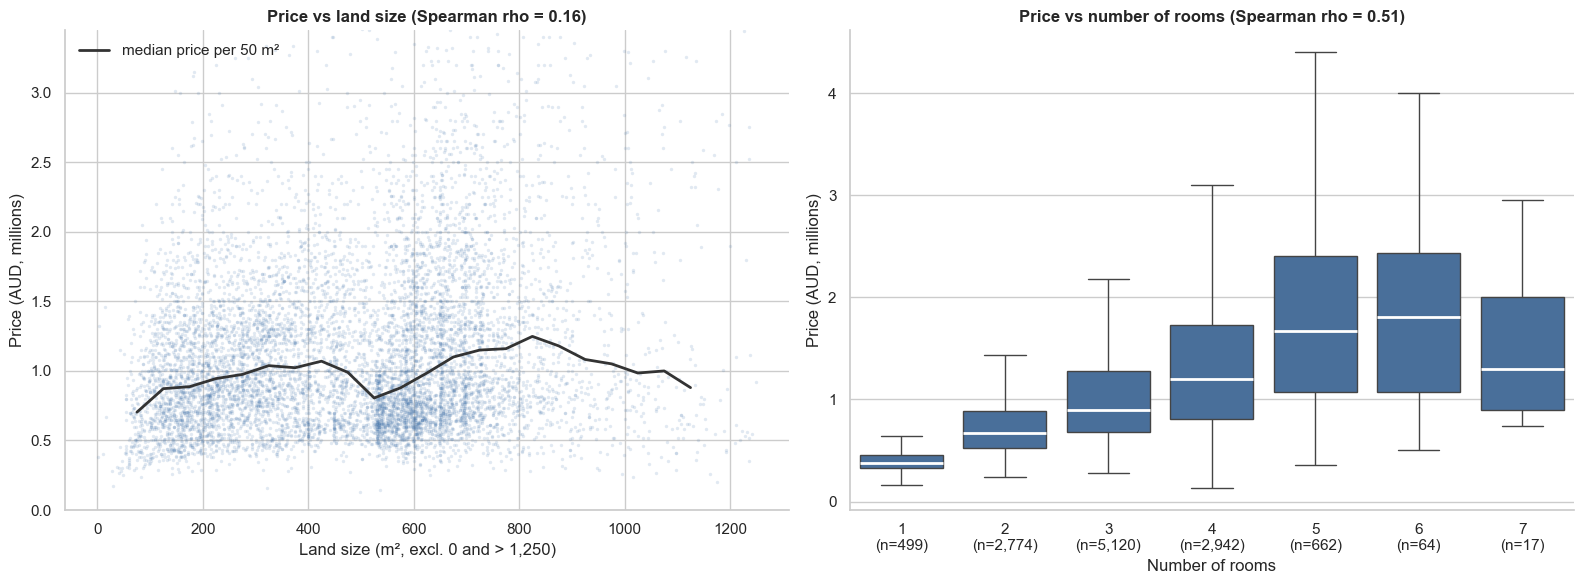

In [41]:
# Bivariate Analysis (3/4): Price vs land size and Price vs number of rooms
# Spearman correlation (rho): -1 to +1, how strongly price goes up (or down) with the other
# variable. It uses ranks, so it is not thrown off by the skewed price distribution.

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Price vs land size: same range as the trimmed univariate plot (LAND_MIN, LAND_MAX).
# 0 m² is left out: those are mostly units, which have no land of their own.
land = biv[(biv["Landsize"] > LAND_MIN) & (biv["Landsize"] <= LAND_MAX)]
rho_land = land["Landsize"].corr(land["PriceM"], method="spearman")

ax = axes[0]
ax.scatter(land["Landsize"], land["PriceM"], s=6, alpha=0.15, color=BAR_COLOR, linewidths=0)
# Median price per 50 m² of land: shows the trend through the cloud of points
# (only bins with at least 30 sales, so a few sales at the edge don't make the line jump)
land_bins = (land["Landsize"] // 50) * 50 + 25
trend = land.groupby(land_bins)["PriceM"].agg(["median", "count"])
trend = trend[trend["count"] >= 30]
ax.plot(trend.index, trend["median"], color=INK, linewidth=2, label="median price per 50 m²")
ax.legend(loc="upper left", frameon=False)
# A few very expensive sales stretch the axis: show up to the 99th percentile of price
ax.set_ylim(0, land["PriceM"].quantile(0.99))
ax.set_title(f"Price vs land size (Spearman rho = {rho_land:.2f})", fontweight="bold")
ax.set_xlabel(f"Land size (m², excl. 0 and > {LAND_MAX:,})")
ax.set_ylabel("Price (AUD, millions)")

# Price vs rooms: one box per number of rooms; the number of sales is shown under each box
rho_rooms = biv["Rooms"].corr(biv["PriceM"], method="spearman")
room_counts = biv["Rooms"].value_counts().sort_index()

ax = axes[1]
sns.boxplot(data=biv, x="Rooms", y="PriceM", order=room_counts.index, color=BAR_COLOR,
            showfliers=False, medianprops={"color": "white", "linewidth": 2}, ax=ax)
ax.set_xticks(range(len(room_counts)))
ax.set_xticklabels([f"{r}\n(n={n:,})" for r, n in room_counts.items()])
ax.set_title(f"Price vs number of rooms (Spearman rho = {rho_rooms:.2f})", fontweight="bold")
ax.set_xlabel("Number of rooms")
ax.set_ylabel("Price (AUD, millions)")

sns.despine()
plt.tight_layout()
save_fig("12_bivariate_price_vs_land_and_rooms")
plt.show()


Figure saved to figures\13_bivariate_age_by_suburb.png


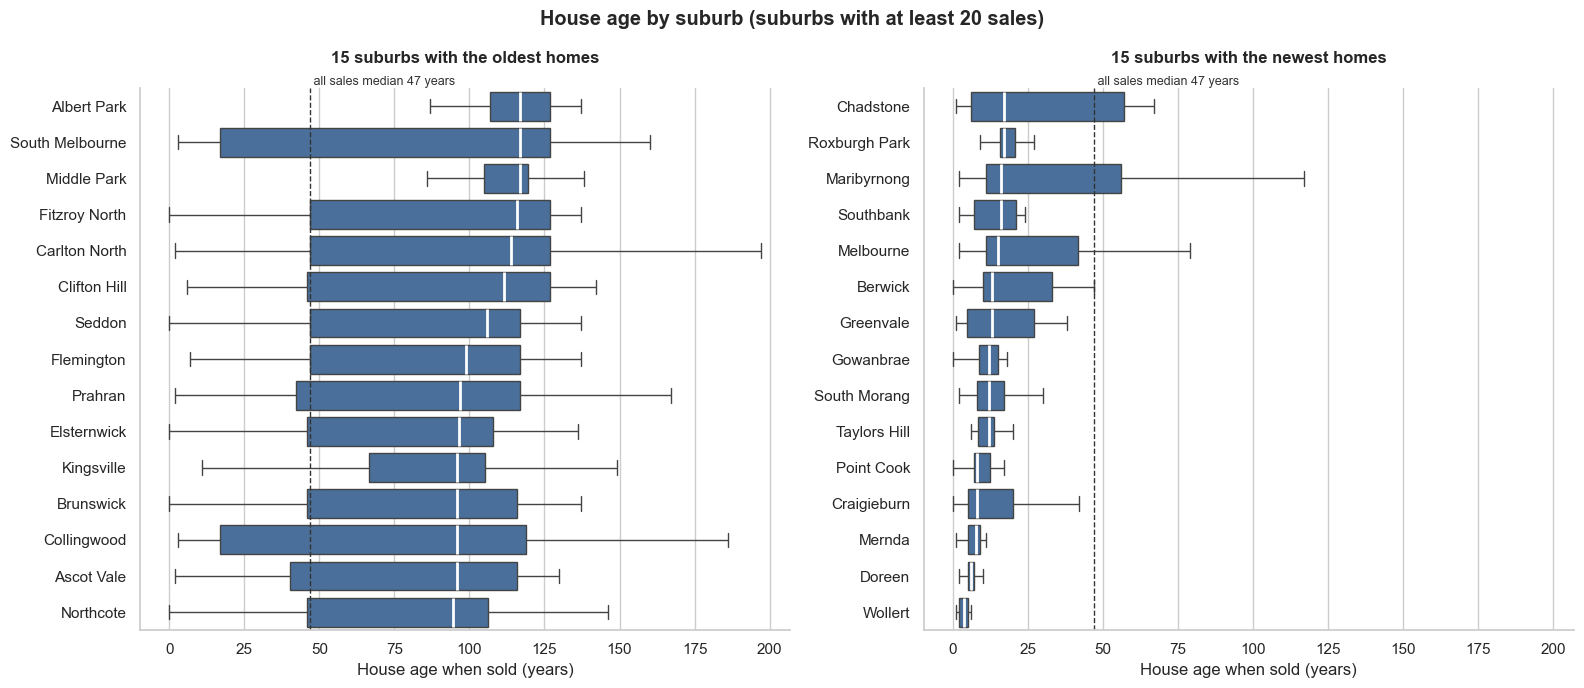

In [42]:
# Bivariate Analysis (4/4): House age by suburb
# Same idea as price by suburb: the 15 suburbs with the oldest homes vs the 15 with the newest
# (by median age when sold), only suburbs with at least MIN_SALES sales.

age_median_all = biv["HouseAge"].median()
suburb_data, oldest, newest = highest_and_lowest("HouseAge")

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharex=True)
for ax, names, title in [(axes[0], oldest, f"{TOP_N} suburbs with the oldest homes"),
                         (axes[1], newest, f"{TOP_N} suburbs with the newest homes")]:
    box_by_group(suburb_data, "HouseAge", "Suburb", names, ax,
                 overall=age_median_all, overall_label=f"all sales median {age_median_all:.0f} years")
    ax.set_title(title, fontweight="bold", pad=18)
    ax.set_xlabel("House age when sold (years)")

fig.suptitle(f"House age by suburb (suburbs with at least {MIN_SALES} sales)", fontweight="bold")
sns.despine()
plt.tight_layout()
save_fig("13_bivariate_age_by_suburb")
plt.show()


###  Correlation

The **correlation coefficient** measures how strongly two numeric variables move together, from **−1** (one goes up, the other goes down) through **0** (no relation) to **+1** (they go up together).

We use **Spearman** correlation instead of the default (Pearson): it works with the *ranking* of the values, so it is not fooled by skewed distributions and outliers.

A **heatmap** shows the whole correlation matrix as colours. The matrix is symmetric (corr(A, B) = corr(B, A)), so we hide the upper triangle with a **mask**.

Figure saved to figures\14_correlation_heatmap.png


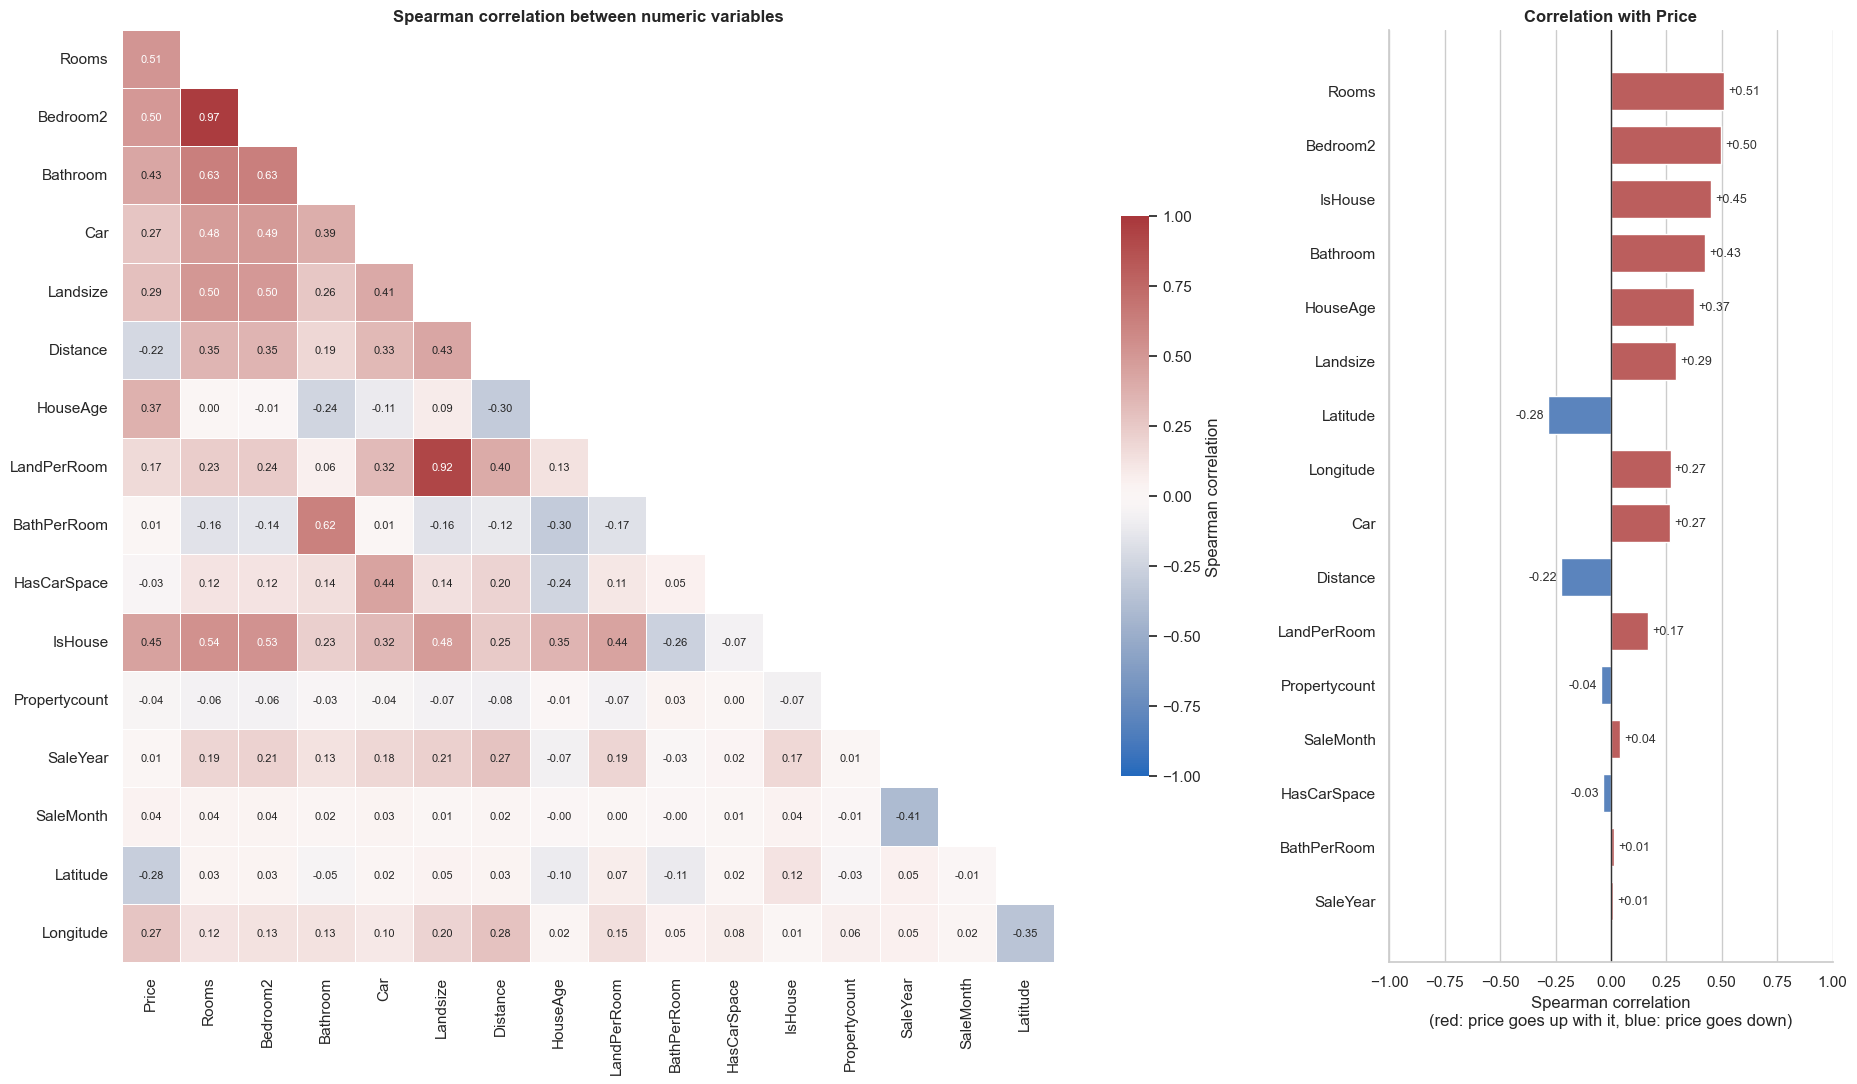

In [43]:
# Correlation: Spearman heatmap of every numeric variable that could affect Price
# Left:  full correlation matrix (lower triangle only)
# Right: just the column for Price, sorted by strength -> which variables matter most for price

corr_cols = ["Price", "Rooms", "Bedroom2", "Bathroom", "Car", "Landsize", "Distance",
             "HouseAge", "LandPerRoom", "BathPerRoom", "HasCarSpace", "IsHouse",
             "Propertycount", "SaleYear", "SaleMonth", "Latitude", "Longitude"]
# YearBuilt is left out: it holds the same information as HouseAge (just with the opposite sign)

# .astype(float): the Int64 columns become normal numbers so .corr() can use them
corr = df_clean[corr_cols].astype(float).corr(method="spearman")

# Drop the first row and last column: after masking they would be empty
corr_lower = corr.iloc[1:, :-1]
# mask = True above the diagonal -> those cells are hidden (they repeat the lower triangle)
mask = np.triu(np.ones_like(corr_lower, dtype=bool), k=1)

# Diverging colours: blue = negative, red = positive, white = 0 (no relation)
corr_cmap = sns.color_palette("vlag", as_cmap=True)

fig = plt.figure(figsize=(20, 11))
grid = fig.add_gridspec(1, 2, width_ratios=[3, 1])
ax_heat = fig.add_subplot(grid[0])
ax_price = fig.add_subplot(grid[1])

sns.heatmap(corr_lower, mask=mask, cmap=corr_cmap, vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 8},
            linewidths=0.5, linecolor="white", square=True,
            cbar_kws={"shrink": 0.6, "label": "Spearman correlation"}, ax=ax_heat)
ax_heat.set_title("Spearman correlation between numeric variables", fontweight="bold")
ax_heat.grid(False)   # the whitegrid style would draw lines through the cells

# Correlation of each variable with Price, strongest (positive or negative) on top
price_corr = corr["Price"].drop("Price").sort_values(key=abs)
bar_colors = [corr_cmap(0.9) if r > 0 else corr_cmap(0.1) for r in price_corr]

ax_price.barh(price_corr.index, price_corr.values, color=bar_colors, height=0.7)
ax_price.bar_label(ax_price.containers[0], fmt="{:+.2f}", padding=3, fontsize=9, color=INK)
ax_price.axvline(0, color=INK, linewidth=1)
ax_price.set_xlim(-1, 1)
ax_price.set_title("Correlation with Price", fontweight="bold")
ax_price.set_xlabel("Spearman correlation\n(red: price goes up with it, blue: price goes down)")
ax_price.grid(axis="y", visible=False)

sns.despine(ax=ax_price)
plt.tight_layout()
save_fig("14_correlation_heatmap")
plt.show()


## 6.d. Multivariate analysis

Figure saved to figures\15_multivariate_maps.png


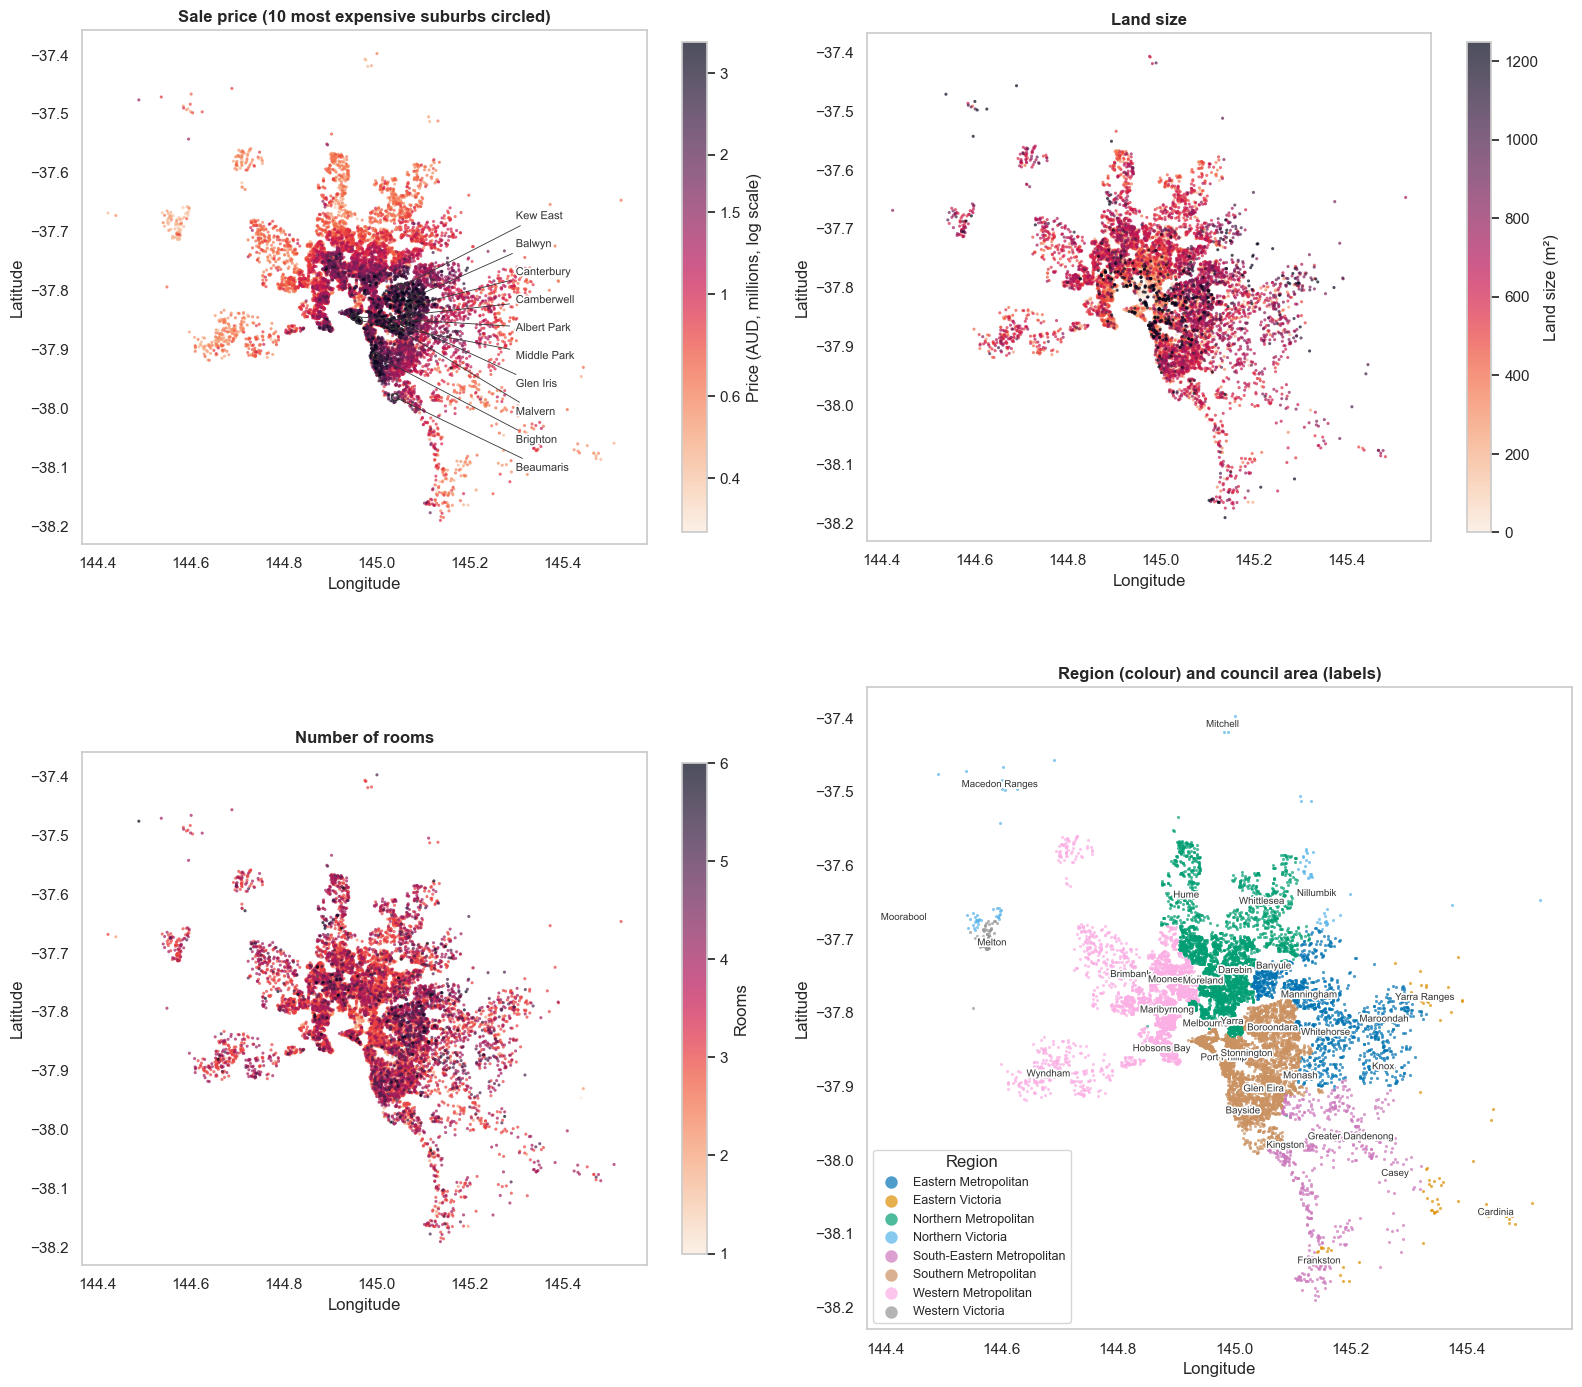

In [44]:
# Multivariate Analysis (1/3): Where are the houses? Maps from Longitude / Latitude
# Each dot is one sale, placed at its real location. The same dots are coloured 4 ways:
# price, land size, rooms, and region (with council area names on top).
from matplotlib.colors import LogNorm
import matplotlib.patheffects as pe

geo = biv.dropna(subset=["Latitude", "Longitude"])

# 1 degree of longitude is shorter than 1 degree of latitude this far south:
# this aspect ratio keeps the map from looking stretched
MAP_ASPECT = 1 / np.cos(np.radians(geo["Latitude"].mean()))
MAP_CMAP = "rocket_r"                        # light = low, dark = high
# Colours for categories (regions, property type); colour 9 (sky blue) replaces colour 3,
# which looked too much like the orange next to it
CAT_PALETTE = [sns.color_palette("colorblind")[i] for i in [0, 1, 2, 9, 4, 5, 6, 7]]
OUTLINE = [pe.withStroke(linewidth=2.5, foreground="white")]   # white outline keeps labels readable

def map_scatter(ax, data, color_col, title, label, **color_kws):
    # Scatter of one variable on the map; highest values are drawn last so they stay visible
    data = data.dropna(subset=[color_col]).sort_values(color_col)
    dots = ax.scatter(data["Longitude"], data["Latitude"], c=data[color_col].astype(float),
                      cmap=MAP_CMAP, s=5, alpha=0.7, linewidths=0, **color_kws)
    ax.set_title(title, fontweight="bold")
    return fig.colorbar(dots, ax=ax, shrink=0.7, label=label)

def callout_places(ax, data, group_col, names, text_x):
    # For places too close together to label in place: circle each one and write its
    # name in a column at text_x, with a thin line pointing to it
    centres = (data[data[group_col].isin(names)].groupby(group_col)[["Longitude", "Latitude"]]
               .median().sort_values("Latitude", ascending=False))
    text_ys = np.linspace(centres["Latitude"].max() + 0.12, centres["Latitude"].min() - 0.12, len(centres))
    for (name, (lon, lat)), text_y in zip(centres.iterrows(), text_ys):
        ax.scatter(lon, lat, s=25, facecolors="none", edgecolors=INK, linewidths=1)
        ax.annotate(name, xy=(lon, lat), xytext=(text_x, text_y), fontsize=8, color=INK,
                    va="center", path_effects=OUTLINE,
                    arrowprops={"arrowstyle": "-", "color": INK, "linewidth": 0.6})

def label_places(ax, data, group_col, names, fontsize=8):
    # Write each name at the middle (median position) of its sales
    centres = data[data[group_col].isin(names)].groupby(group_col)[["Longitude", "Latitude"]].median()
    for name, (lon, lat) in centres.iterrows():
        ax.text(lon, lat, name, fontsize=fontsize, ha="center", va="center",
                color=INK, path_effects=OUTLINE)

fig, axes = plt.subplots(2, 2, figsize=(16, 15))
axes = axes.flatten()

# 1. Price (log colour scale, so cheap and mid-range areas are not all the same colour)
cbar = map_scatter(axes[0], geo, "PriceM", "Sale price (10 most expensive suburbs circled)",
                   "Price (AUD, millions, log scale)",
                   norm=LogNorm(geo["PriceM"].quantile(0.01), geo["PriceM"].quantile(0.99)))
price_ticks = [0.4, 0.6, 1, 1.5, 2, 3]
cbar.set_ticks(price_ticks, labels=[f"{t:g}" for t in price_ticks])   # 0.4 ... 3 instead of 10^0
cbar.minorticks_off()
# priciest comes from the bivariate suburb plot; names go in a column east of the city
callout_places(axes[0], geo, "Suburb", priciest[:10], text_x=145.3)

# 2. Land size (same 0 - LAND_MAX range as before; 0 m² units are kept, they show the inner city)
map_scatter(axes[1], geo, "Landsize", "Land size", "Land size (m²)", vmin=0, vmax=LAND_MAX)

# 3. Number of rooms
map_scatter(axes[2], geo, "Rooms", "Number of rooms", "Rooms", vmin=1, vmax=6)

# 4. Region (colour) and council area (labels)
for color, (region, data) in zip(CAT_PALETTE, geo.groupby("Regionname", observed=True)):
    axes[3].scatter(data["Longitude"], data["Latitude"], s=5, alpha=0.7, linewidths=0,
                    color=color, label=region)
axes[3].legend(title="Region", markerscale=4, fontsize=9, loc="lower left")
label_places(axes[3], geo, "Council", geo["Council"].unique(), fontsize=7)
axes[3].set_title("Region (colour) and council area (labels)", fontweight="bold")

for ax in axes:
    ax.set_aspect(MAP_ASPECT)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.grid(False)

plt.tight_layout()
save_fig("15_multivariate_maps")
plt.show()


Figure saved to figures\16_multivariate_pairplot.png


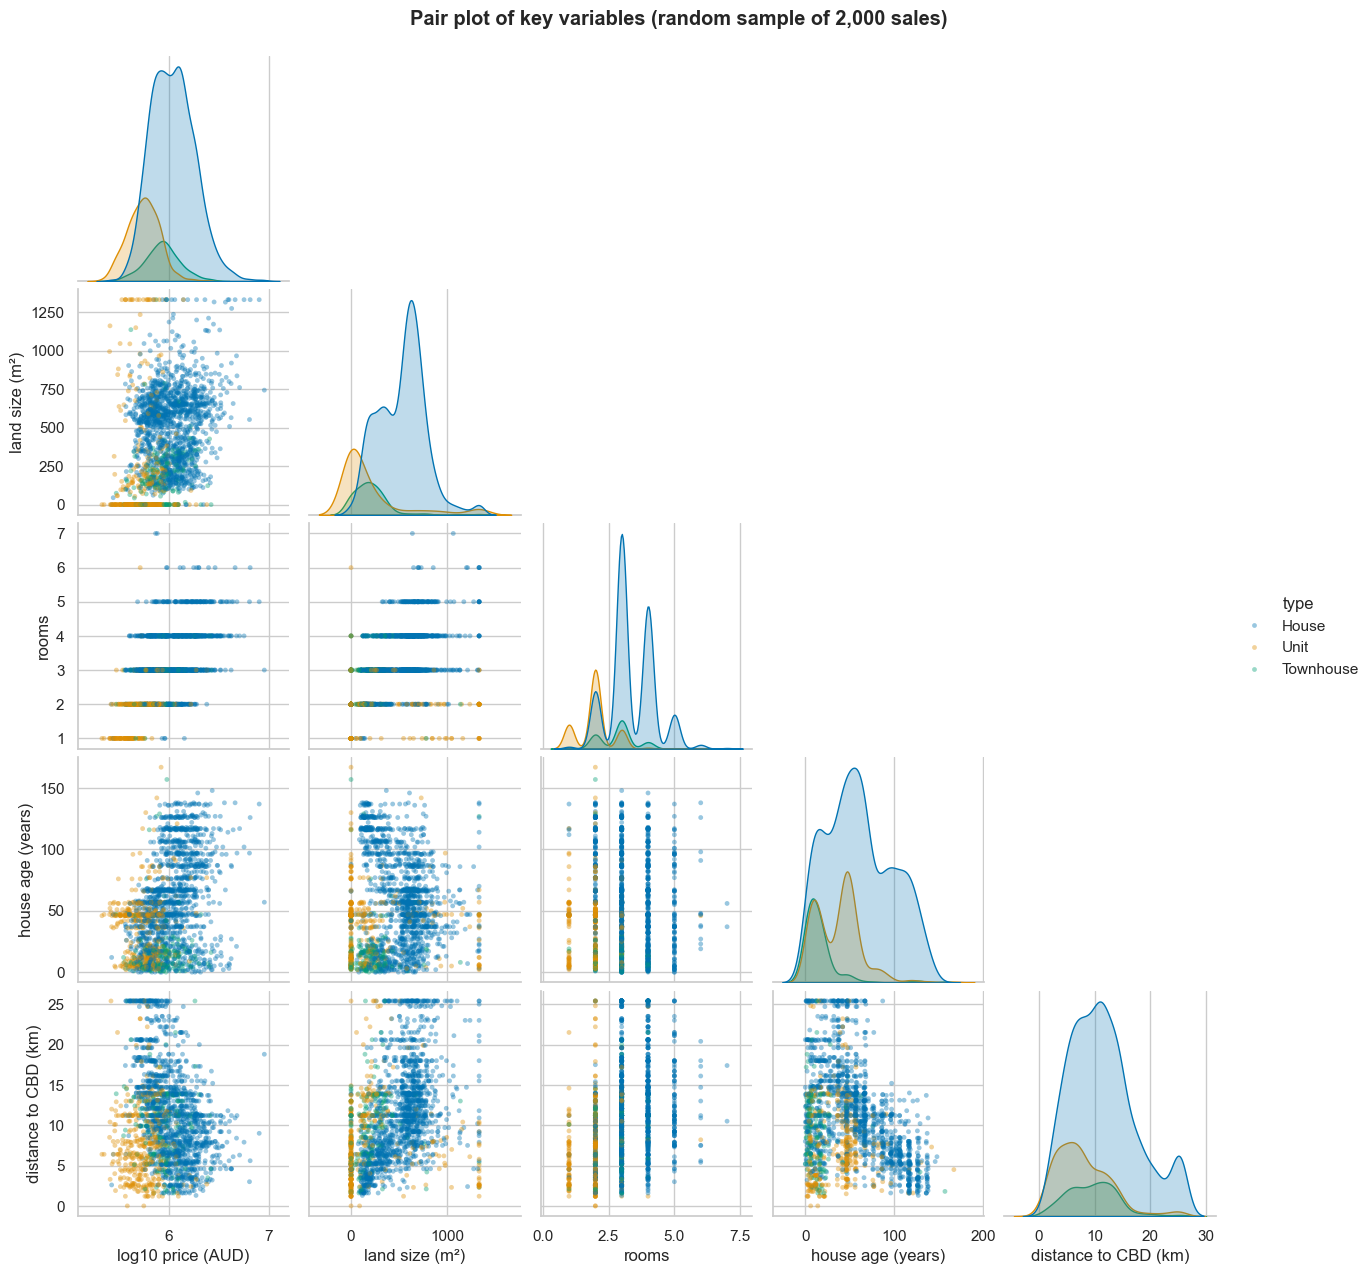

In [45]:
# Multivariate Analysis (2/3): Pair plot of key variables, coloured by property type
# Every variable against every other variable; the diagonal shows each one's distribution.
# A random sample of 2,000 sales keeps the plot readable (12,000 dots would be one big blob).

pair_sample = biv.dropna(subset=["Landsize"]).sample(2000, random_state=RANDOM_STATE)
pair_data = pd.DataFrame({
    "log10 price (AUD)": np.log10(pair_sample["Price"]),
    "land size (m²)": pair_sample["Landsize"],
    "rooms": pair_sample["Rooms"].astype(float),
    "house age (years)": pair_sample["HouseAge"].astype(float),
    "distance to CBD (km)": pair_sample["Distance"],
    "type": pair_sample["Type"].astype(str).map(type_names),   # House / Unit / Townhouse
})

# corner=True draws only the lower half (the upper half would be a mirror image)
grid = sns.pairplot(pair_data, hue="type", hue_order=["House", "Unit", "Townhouse"],
                    palette=CAT_PALETTE[:3], corner=True,
                    plot_kws={"alpha": 0.4, "s": 12, "linewidth": 0})
grid.figure.suptitle("Pair plot of key variables (random sample of 2,000 sales)",
                     y=1.02, fontweight="bold")
save_fig("16_multivariate_pairplot")
plt.show()


Figure saved to figures\17_multivariate_price_rooms_by_council.png


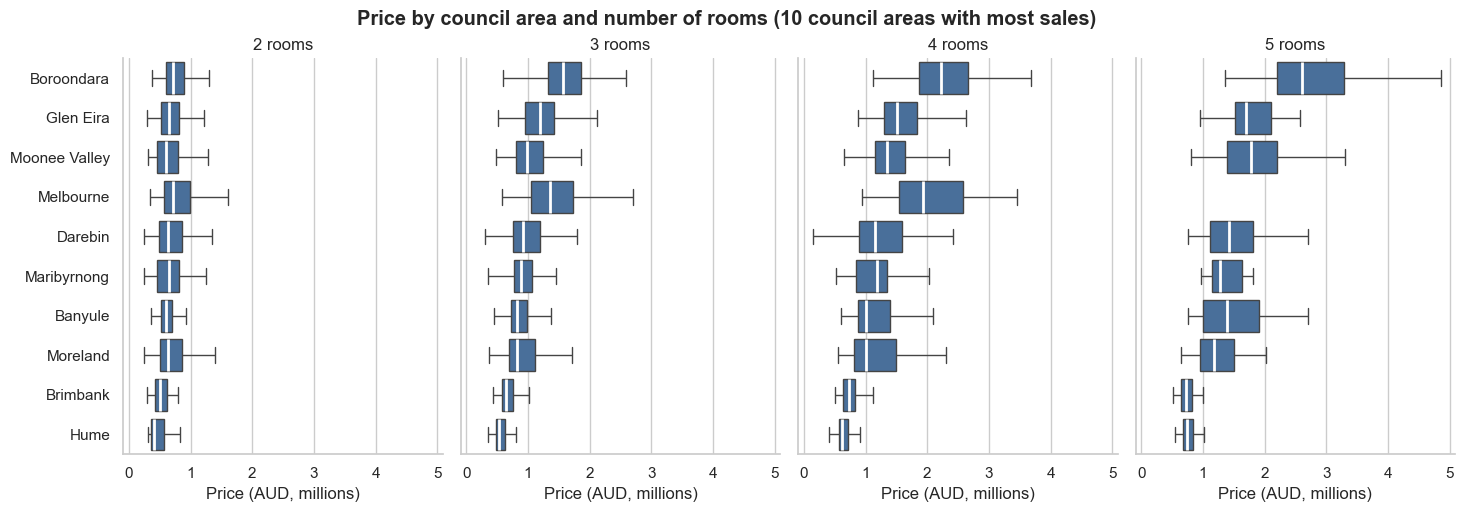

In [46]:
# Multivariate Analysis (3/3): Price by council area, for each number of rooms
# Three variables at once: council area (y), price (x) and rooms (one small plot each).
# Every panel lists the councils in the same order, so you can read across a row and compare,
# for example, what a 5-room property costs in Boroondara vs Darebin.
# Same box as before: middle 50% of prices, white line = median.

N_COUNCILS = 10            # council areas with the most sales
MIN_SALES_PER_BOX = 10     # fewer sales than this -> no box (a box from 2-3 sales is misleading)
ROOMS_TO_SHOW = [2, 3, 4, 5]

top_councils = biv["Council"].value_counts().head(N_COUNCILS).index
facet_data = biv[biv["Council"].isin(top_councils) & biv["Rooms"].isin(ROOMS_TO_SHOW)]

# Keep only council + rooms combinations with enough sales
box_size = facet_data.groupby(["Council", "Rooms"])["PriceM"].transform("size")
facet_data = facet_data[box_size >= MIN_SALES_PER_BOX]

# Order councils from most to least expensive (median price of all their sales)
council_order = facet_data.groupby("Council")["PriceM"].median().sort_values(ascending=False).index

grid = sns.catplot(
    data=facet_data, x="PriceM", y="Council", order=council_order,
    col="Rooms", col_order=ROOMS_TO_SHOW,   # one small plot per number of rooms, side by side
    kind="box", showfliers=False,
    height=5, aspect=0.75, color=BAR_COLOR,
    medianprops={"color": "white", "linewidth": 2},
)
grid.set_axis_labels("Price (AUD, millions)", "")
grid.set_titles("{col_name} rooms")
for ax in grid.axes.flat:
    ax.grid(axis="x", visible=True)
grid.figure.suptitle(f"Price by council area and number of rooms ({N_COUNCILS} council areas with most sales)",
                     y=1.02, fontweight="bold")
save_fig("17_multivariate_price_rooms_by_council")
plt.show()


# 7. Save a clean, model-ready dataset.

In [47]:
# Save the cleaned dataset (with the new features) as a CSV in the data folder
clean_path = DATA_DIR / "melbourne_house_prices_clean.csv"

# index=False: the row numbers are not data, so they are not written to the file
df_clean.to_csv(clean_path, index=False)
print(f"Saved {df_clean.shape[0]:,} rows and {df_clean.shape[1]} columns to {clean_path}")

# Check: read the file back and make sure nothing was lost
# (parse_dates turns the Date text back into real dates)
check = pd.read_csv(clean_path, parse_dates=["Date"])
print(f"Read back: {check.shape[0]:,} rows and {check.shape[1]} columns")
check.head()

Saved 12,078 rows and 28 columns to data\melbourne_house_prices_clean.csv
Read back: 12,078 rows and 28 columns


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,YearBuilt,CouncilArea,Latitude,Longitude,Regionname,Propertycount,SaleYear,SaleMonth,HouseAge,LandPerRoom,BathPerRoom,HasCarSpace,IsHouse,DistanceZone
0,Abbotsford,25 Bloomburg St,2,h,"1,035,000.00",S,Biggin,2016-02-04,2.50,3067,2,1.00,0,156.00,1900,Yarra City Council,-37.81,144.99,Northern Metropolitan,4019,2016,2,116,78.00,0.50,0,1,Inner (0-5 km)
1,Abbotsford,5 Charles St,3,h,"1,465,000.00",SP,Biggin,2017-03-04,2.50,3067,3,2.00,0,134.00,1900,Yarra City Council,-37.81,144.99,Northern Metropolitan,4019,2017,3,117,44.67,0.67,0,1,Inner (0-5 km)
2,Abbotsford,55a Park St,4,h,"1,600,000.00",VB,Nelson,2016-06-04,2.50,3067,3,1.00,2,120.00,2014,Yarra City Council,-37.81,144.99,Northern Metropolitan,4019,2016,6,2,30.00,0.25,1,1,Inner (0-5 km)
3,Abbotsford,124 Yarra St,3,h,"1,876,000.00",S,Nelson,2016-05-07,2.50,3067,4,2.00,0,245.00,1910,Yarra City Council,-37.80,145.00,Northern Metropolitan,4019,2016,5,106,81.67,0.67,0,1,Inner (0-5 km)
4,Abbotsford,98 Charles St,2,h,"1,636,000.00",S,Nelson,2016-10-08,2.50,3067,2,1.00,2,256.00,1890,Yarra City Council,-37.81,145.00,Northern Metropolitan,4019,2016,10,126,128.00,0.50,1,1,Inner (0-5 km)


## Conclusions for EDA

### The data after cleaning
- We kept **12,078 of 34,857 sales** (28 columns, including 8 engineered features) covering **February 2016 to March 2018**. Most rows were dropped because the price (the target) or the year built was missing, so the clean set is smaller but complete.
- The typical sale is a **3-room house** (72% houses, 19% units, 9% townhouses) about **47 years old** on **460 m²** of land, **5–15 km from the CBD** (65% of sales). 94% have at least one car space.
- **Price is right-skewed**: median **AUD 0.89 M** vs mean 1.08 M, with a long tail of multi-million sales. A **log scale** makes it close to normal, so we model `log10(price)`.

### What drives price
1. **Location is the biggest factor.** Location effects are strong enough to swamp most other variables:
   - Median prices range from about AUD 0.4 M (Melton, Mitchell) to 1.7 M (Boroondara) between council areas.
   - The 15 most expensive suburbs (Canterbury, Malvern, Middle Park, Balwyn, …) all lie in the **inner east and along the bay**. The cheapest (Melton South, Meadow Heights, Craigieburn, …) are on the **outer west and north**.
   - Price falls with **distance to the CBD** (median 1.01 M inner, 0.94 M middle, 0.72 M outer).
2. **Size matters next**: price rises steadily with **rooms** (Spearman ρ = 0.51), **bedrooms** (0.50) and **bathrooms** (0.43). The median goes from ~0.4 M for 1 room to ~1.8 M for 6 rooms.
3. **Property type**: houses (median 1.03 M) sell for more than townhouses (0.84 M) and units (0.55 M); `IsHouse` correlates 0.45 with price.
4. **Location and size interact**: in Boroondara a 5-room home has a median of ~2.6 M; in Brimbank or Hume it costs under 1 M. **The same number of rooms is worth very different amounts in different areas**, so a model needs both.
5. **Older homes sell for more** (ρ = 0.37), but not because age adds value. Old homes are concentrated in expensive inner suburbs (Albert Park, South Melbourne, Fitzroy North are 100+ years old); new homes are in cheaper outer growth areas (Wollert, Doreen, Mernda).

### What barely matters
- **Land size** has only a weak link with price (ρ = 0.16–0.29). Big blocks are mostly in cheaper outer areas, while small or 0 m² lots (units) are in the expensive inner city.
- **Sale month and year**, **Propertycount**, **BathPerRoom** and **HasCarSpace** are all close to 0. Sales peak in spring (September–October) and drop in December–January, but the price stays the same.

### Points to carry into modelling
- **Redundant pairs**: `Rooms`/`Bedroom2` (ρ = 0.97) and `Landsize`/`LandPerRoom` (ρ = 0.92) carry almost the same information. Keep one of each pair, or use a model that handles correlated features (e.g., Ridge, tree-based models).
- **Location features** (`Suburb`, `CouncilArea`, `Regionname`, latitude/longitude, `Distance`) should be included and encoded carefully. Suburb has 300+ categories, so it suits **target encoding** better than one-hot encoding.
- **Limitations**:
  - Landsize and a few count columns were **capped** at their IQR bounds, and 0 m² is common for units.
  - Dropping rows with a missing `YearBuilt` removed more than half of the priced sales, which may bias the sample.
  - The data covers only 2016–2018, so conclusions may not hold for today's market.

### ----- END OF DAY 1 ASSIGNMENT -----

## Day3: Application of unsupervised learning methods.

### Learning goals
By the end of this notebook:
1. Explain why **distance** and **scaling** are at the heart of unsupervised learning.
2. Describe how **K-Means**, **hierarchical clustering** and **DBSCAN** work, and **when to use which**.
3. Evaluate clusters **without labels** (elbow, silhouette) and, above all, **interpret** them with domain knowledge.
4. Use **PCA** to understand and compress data, and **t-SNE / UMAP** to visualise high-dimensional data, knowing their traps.
5. Apply these tools to typologies, energy profiles, point clouds and urban data.
6. **Save** a clustering model, reuse it on new data, and prepare it (and a dataset) for **publication**.

### Goals

1. Data Split: Split the dataset into training and test sets (80-20) to honestly evaluate model performance on unseen data.    

2. Cross-Validation & Data Leakage Prevention: Implement cross-validation (KFold) to ensure model stability and prevent data leakage.      

3. Pipeline Automation: Build clean Scikit-learn pipelines to handle missing values, scale numeric variables, and encode categories (OneHotEncoder) without errors.       

4. Model Zoo / Comparison: Compare multiple algorithms (from Linear Regression to Random Forest and Gradient Boosting) to scientifically select the best one.      

5. Hyperparameter Tuning & Final Evaluation: Optimize hyperparameters of the winning model using GridSearchCV and verify its success using robust metrics ($R^2 = 0.89$, MAE, RMSE, MAPE).     

6. Feature Interpretation: Analyze feature importance to conclude that geographical location and property size are the key drivers determining house prices.     

7. Saving the final model

Importing libraries for Pre-processing, PCA, Clustering.

In [48]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline

1. Defining numeric and categorical features for the clustering. Then we drop the irrelevant data.

In [64]:
# 8.1. Select the features used for clustering
# Numeric property features + Price, and Type as the only categorical feature.
# No raw Latitude / Longitude (location stays a result, not an input)
numeric_features = [
    "Rooms",          # number of rooms
    "Bathroom",       # number of bathrooms
    "Car",            # number of car spaces
    "Landsize",       # land size (m²)
    "HouseAge",       # age of the house when sold (years)
    "Distance",       # distance to the CBD (km)
    "Price",          # sale price (AUD)
    "Bedroom2"        # no. of bedrooms
]

categorical_features = [
    "Type",           # h = house, t = townhouse, u = unit (one-hot encoded in the pipeline)
]

# Keep only these columns, so nothing else can get into the model by accident.
# .astype(float) turns the nullable Int64 columns into plain floats (missing -> NaN),
# which scikit-learn and the plotting libraries handle without problems.
X = pd.concat(
    [df_clean[numeric_features].astype(float), df_clean[categorical_features].astype(str)],
    axis=1,
)
assert not {"Latitude", "Longitude"} & set(X.columns)

print(f"X: {X.shape[0]:,} rows x {X.shape[1]} columns")
print("\nMissing values per feature (filled with the median in the pipeline):")
print(X.isna().sum())
print("\nSales per property type:")
print(X["Type"].value_counts())

X.describe().T

X: 12,078 rows x 9 columns

Missing values per feature (filled with the median in the pipeline):
Rooms          0
Bathroom       1
Car            0
Landsize    1463
HouseAge       0
Distance       0
Price          0
Bedroom2       0
Type           0
dtype: int64

Sales per property type:
Type
h    8731
u    2312
t    1035
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
Rooms,"12,078.00",3.06,0.96,1.00,2.00,3.00,4.00,7.00
Bathroom,"12,077.00",1.63,0.69,1.00,1.00,2.00,2.00,4.00
Car,"12,078.00",1.67,0.87,0.00,1.00,2.00,2.00,4.00
Landsize,"10,615.00",450.33,310.32,0.00,197.00,460.00,651.00,"1,332.00"
HouseAge,"12,078.00",50.10,36.03,-2.00,17.00,47.00,68.00,197.00
Distance,"12,078.00",10.97,6.02,0.00,6.40,10.30,14.00,25.40
Price,"12,078.00","1,077,092.20","671,384.25","85,000.00","632,000.00","885,000.00","1,320,000.00","9,000,000.00"
Bedroom2,"12,078.00",3.05,0.96,0.00,2.00,3.00,4.00,7.00


2. Pre-processing: Scaling and Imupation of the data for the model.

In [65]:
# 2. Preprocessing transformer: scale the numeric features, one-hot encode the categories
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Fill gaps with the median before scaling (Landsize has some missing values;
# StandardScaler and clustering both fail on NaN)
numeric_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        # sparse_output=False gives a normal array, which PCA and plotting need
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
    ]
)

X_prepared = preprocessor.fit_transform(X)
feature_names = preprocessor.get_feature_names_out()

print(f"X_prepared: {X_prepared.shape[0]:,} rows x {X_prepared.shape[1]} columns")
pd.DataFrame(X_prepared, columns=feature_names).head()


X_prepared: 12,078 rows x 11 columns


,num__Rooms,num__Bathroom,num__Car,num__Landsize,num__HouseAge,num__Distance,num__Price,num__Bedroom2,cat__Type_h,cat__Type_t,cat__Type_u
0,-1.11,-0.92,-1.92,-1.02,1.83,-1.41,-0.06,-1.09,1.00,0.00,0.00
1,-0.06,0.54,-1.92,-1.09,1.86,-1.41,0.58,-0.05,1.00,0.00,0.00
2,0.98,-0.92,0.37,-1.14,-1.34,-1.41,0.78,-0.05,1.00,0.00,0.00
3,-0.06,0.54,-1.92,-0.71,1.55,-1.41,1.19,0.99,1.00,0.00,0.00
4,-1.11,-0.92,0.37,-0.67,2.11,-1.41,0.83,-1.09,1.00,0.00,0.00


In [63]:
#EXTRA CODE FOR PIPELINE FOR CLUSTERING AND PCA COMBINED... REMOVED AS WE DID IT SEPARATELY AGAIN.

# # 3. Full pipeline: preprocessing -> PCA -> K-Means clustering
# from sklearn.cluster import KMeans
# from sklearn.decomposition import PCA

# N_CLUSTERS = 5

# home_clustering_pipeline = Pipeline([
#     ("preprocessor", preprocessor),
#     ("pca", PCA(n_components=0.95, random_state=RANDOM_STATE)),   # keep 95% of the variance
#     ("kmeans", KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=RANDOM_STATE)),
# ])

# # fit_predict runs every step and returns one cluster label per sale
# cluster_labels = home_clustering_pipeline.fit_predict(X)

# pca = home_clustering_pipeline.named_steps["pca"]
# print(f"PCA kept {pca.n_components_} of {X_prepared.shape[1]} components "
#       f"({pca.explained_variance_ratio_.sum():.1%} of the variance)")

# # Attach the labels to the original (unscaled) features so each cluster can be read in real units
# clustered = X.assign(Cluster=cluster_labels)
# print("\nSales per cluster:")
# print(clustered["Cluster"].value_counts().sort_index())

# # Profile: typical numeric values and the most common category in each cluster
# profile = clustered.groupby("Cluster").agg(
#     **{f"median_{c}": (c, "median") for c in numeric_features},
#     **{f"top_{c}": (c, lambda s: s.mode().iat[0]) for c in categorical_features},
# )
# profile


3. PCA with selected features.

In [66]:
# PCA on the numeric features only (raw Latitude / Longitude are already excluded from X)
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_features = ["Landsize", "Rooms", "HouseAge", "Distance", "Bathroom", "Car", "Price", "Bedroom2" ]

# 1. Fill gaps with the median, then scale (PCA fails on NaN, and without
#    scaling Landsize in m² would outweigh Rooms just because its numbers are bigger)
X_num = SimpleImputer(strategy="median").fit_transform(X[numeric_features])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_num)

# 2. Apply PCA, keeping as many components as needed for 95% of the variance
pca = PCA(n_components=0.95, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

# How many components were kept and how much variance they explain
print(f"Original features:       {X_scaled.shape[1]}")
print(f"PCA components retained: {X_pca.shape[1]}")
print(f"Explained variance ratio: {pca.explained_variance_ratio_.sum():.4f}")

pc_names = [f"PC{i + 1}" for i in range(pca.n_components_)]
for name, ratio, total in zip(pc_names, pca.explained_variance_ratio_,
                              pca.explained_variance_ratio_.cumsum()):
    print(f"  {name}: {ratio:.1%}  (cumulative {total:.1%})")

# Loadings: how much each original feature contributes to each component
loadings = pd.DataFrame(pca.components_.T, index=numeric_features, columns=pc_names)
loadings.round(2)


Original features:       8
PCA components retained: 6
Explained variance ratio: 0.9595
  PC1: 43.1%  (cumulative 43.1%)
  PC2: 20.6%  (cumulative 63.7%)
  PC3: 11.6%  (cumulative 75.3%)
  PC4: 8.6%  (cumulative 83.9%)
  PC5: 7.4%  (cumulative 91.3%)
  PC6: 4.6%  (cumulative 96.0%)


,PC1,PC2,PC3,PC4,PC5,PC6
Landsize,0.31,-0.09,0.65,0.07,0.65,-0.16
Rooms,0.50,0.05,-0.07,-0.29,-0.20,-0.34
HouseAge,-0.03,0.60,0.48,-0.19,-0.39,0.27
Distance,0.20,-0.57,0.27,-0.34,-0.21,0.60
Bathroom,0.41,0.03,-0.49,0.02,0.26,0.43
Car,0.33,-0.16,0.15,0.81,-0.43,-0.01
Price,0.31,0.52,-0.06,0.17,0.22,0.35
Bedroom2,0.50,0.04,-0.07,-0.29,-0.21,-0.35


Scatter plot for type of house.

Figure saved to figures\18_pca_scatter.png


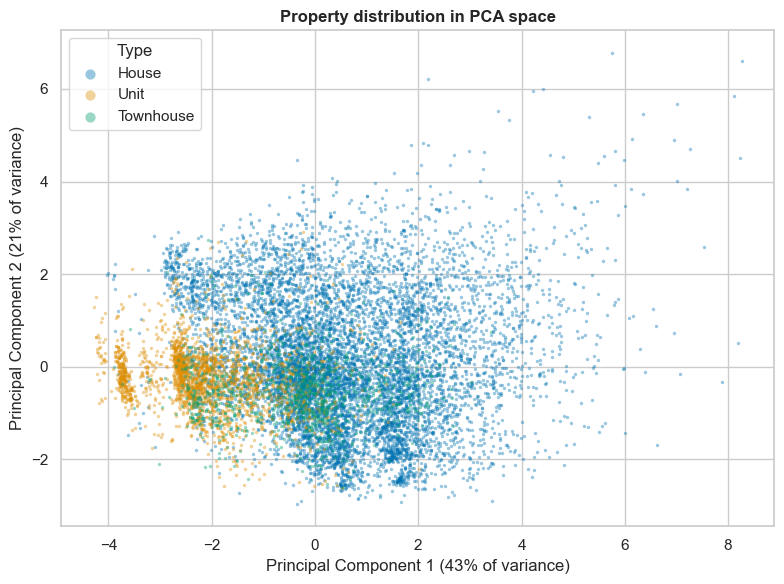

In [ ]:
# PCA scatter: every sale placed by its first two principal components.
# Colour = property type, to show whether the components separate houses, units and townhouses.
import matplotlib.pyplot as plt

pc_var = pca.explained_variance_ratio_   # share of the variance each component explains
types = X["Type"].astype(str).map(type_names)   # House / Unit / Townhouse

fig, ax = plt.subplots(figsize=(8, 6))
for color, name in zip(CAT_PALETTE, ["House", "Unit", "Townhouse"]):
    mask = (types == name).to_numpy()
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], s=6, alpha=0.4, linewidths=0,
               color=color, label=name)

ax.set_xlabel(f"Principal Component 1 ({pc_var[0]:.0%} of variance)")
ax.set_ylabel(f"Principal Component 2 ({pc_var[1]:.0%} of variance)")
ax.set_title("Property distribution in PCA space", fontweight="bold")
ax.legend(title="Type", markerscale=3)

plt.tight_layout()
save_fig("18_pca_categorical_scatter")
plt.show()


In [72]:
# # PCA scatter: every sale placed by its first two principal components.
# # The components come only from numeric_features (no Type), so all points share one colour.
# import matplotlib.pyplot as plt

# pc_var = pca.explained_variance_ratio_   # share of the variance each component explains

# fig, ax = plt.subplots(figsize=(8, 6))
# ax.scatter(X_pca[:, 0], X_pca[:, 1], s=6, alpha=0.4, linewidths=0, color=CAT_PALETTE[0])

# ax.set_xlabel(f"Principal Component 1 ({pc_var[0]:.0%} of variance)")
# ax.set_ylabel(f"Principal Component 2 ({pc_var[1]:.0%} of variance)")
# ax.set_title(f"Property distribution in PCA space ({len(numeric_features)} numeric features)",
#              fontweight="bold")

# plt.tight_layout()
# save_fig("18_pca_numeric_scatter")
# plt.show()

4. Cluster on the PCA components

In [73]:
# 3. Cluster on the PCA component scores
from sklearn.cluster import KMeans

N_CLUSTERS = 4

kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=RANDOM_STATE)
cluster_labels = kmeans.fit_predict(X_pca)

# Add the labels back to the cleaned dataset. X was taken from df_clean, so the rows
# line up; .loc on X.index makes sure each label lands on the right sale.
df_clean.loc[X.index, "cluster"] = cluster_labels
df_clean["cluster"] = df_clean["cluster"].astype(int)

print("Sales per cluster:")
print(df_clean["cluster"].value_counts().sort_index())

# Profile each cluster in real units. Price IS now part of numeric_features,
# so it helped shape the clusters (it is an input here, not only a finding).
cluster_profile = df_clean.groupby("cluster").agg(
    sales=("Price", "size"),
    median_price_M=("Price", lambda s: s.median() / 1e6),   # AUD, millions
    median_rooms=("Rooms", "median"),
    median_bedrooms=("Bedroom2", "median"),
    median_bathrooms=("Bathroom", "median"),
    median_car_spaces=("Car", "median"),
    median_landsize=("Landsize", "median"),
    median_age=("HouseAge", "median"),
    median_distance_km=("Distance", "median"),
    top_type=("Type", lambda s: s.mode().iat[0]),
    top_region=("Regionname", lambda s: s.mode().iat[0]),
)
cluster_profile.round(2)



Sales per cluster:
cluster
0    1968
1    2946
2    4706
3    2458
Name: count, dtype: int64


,sales,median_price_M,median_rooms,median_landsize,median_age,median_distance_km,top_type,top_region
cluster,,,,,,,,
0,1968,1.82,4.00,655.00,57.00,9.70,h,Southern Metropolitan
1,2946,0.59,2.00,98.00,37.00,7.40,u,Southern Metropolitan
2,4706,0.79,3.00,578.00,36.00,14.60,h,Northern Metropolitan
3,2458,1.25,3.00,325.00,98.00,6.20,h,Northern Metropolitan


In [ ]:
# Scatterplot of the clusters in REAL units (no PCA axes), so it is easy to read:
#   x = distance to the CBD (km), y = sale price (AUD millions, log scale)
#   small dots = individual sales, big circles = the cluster medians from cluster_profile
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

k = kmeans.n_clusters
colors = CAT_PALETTE[:k]   # same cluster colours as the other cluster figures
data = df_clean.loc[X.index]

fig, ax = plt.subplots(figsize=(12, 8))

# 1. Every sale, faint, so the shape of each cluster shows without hiding the others
for i, color in enumerate(colors):
    part = data[data["cluster"] == i]
    ax.scatter(part["Distance"], part["Price"] / 1e6, s=8, alpha=0.25, linewidths=0,
               color=color, label=f"Cluster {i} ({len(part):,} sales)")

# 2. The typical sale of each cluster (its medians), with a short description next to it
for i, row in cluster_profile.iterrows():
    ax.scatter(row["median_distance_km"], row["median_price_M"], s=260, color=colors[i],
               edgecolors="white", linewidths=2, zorder=3)
    ax.annotate(
        f"Cluster {i}: {row['median_rooms']:.0f} rooms, {row['median_bathrooms']:.0f} bath, "
        f"{row['median_car_spaces']:.0f} car
"
        f"{row['median_landsize']:.0f} m² land, {row['median_age']:.0f} yrs old, type '{row['top_type']}'",
        xy=(row["median_distance_km"], row["median_price_M"]), xytext=(12, 8),
        textcoords="offset points", fontsize=9, fontweight="bold", path_effects=OUTLINE, zorder=4,
    )

ax.set_yscale("log")   # prices are very skewed; log keeps cheap and expensive sales visible
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:g}M"))
ax.set_xlabel("Distance to Melbourne CBD (km)")
ax.set_ylabel("Sale price (AUD millions, log scale)")
ax.set_title("What each cluster looks like: distance vs price
"
             "(big circle = the cluster's typical sale)", fontweight="bold")
ax.legend(markerscale=3, fontsize=9, loc="upper right")
ax.grid(alpha=0.3)

plt.tight_layout()
save_fig("23_cluster_profile_scatter")
plt.show()


In [ ]:
# Give each cluster a descriptive name based on its profile (cluster_profile).
# Names are chosen by rules, not by fixed IDs, so they stay correct if K-Means
# numbers the clusters differently after a re-run.
remaining = list(cluster_profile.index)
profile_names = {}

def take(column, pick, name):
    # Give `name` to the remaining cluster with the smallest (pick="min") or largest (pick="max") value
    values = cluster_profile.loc[remaining, column]
    cluster_id = values.idxmin() if pick == "min" else values.idxmax()
    profile_names[cluster_id] = name
    remaining.remove(cluster_id)

# Order matters: each rule picks from the clusters that are still unnamed
take("median_landsize", "min", "Compact inner-city units")             # little land, mostly units, cheapest
take("median_price_M", "max", "Large premium family houses")          # most rooms, big lots, highest price
take("median_age", "max", "Inner-city heritage houses")               # oldest homes, closest to the CBD
take("median_distance_km", "max", "Affordable outer-suburb houses")   # farthest out, big lots, lower price

# Any extra clusters (if N_CLUSTERS > 4) keep a generic name
for cluster_id in remaining:
    profile_names[cluster_id] = f"Cluster {cluster_id}"

# Show each name next to the numbers that justify it
named_profile = cluster_profile.copy()
named_profile.insert(0, "name", named_profile.index.map(profile_names))
named_profile.round(2)



Assuming:- pca is your fitted PCA object (e.g., pca.fit(X_scaled))- numeric_features is the list of feature names you passed into PCA1. Create a DataFrame for the factor loadingsloadings_df = pd.DataFrame(
pca.components_,
columns=numeric_features,
index=[f'PC{i+1}' for i in range(pca.n_components_)]
)

print("--- Factor Loadings (Weights per Component) ---")
Use display(loadings_df) if working in a Jupyter Notebook, otherwise print(loadings_df)display(loadings_df)
2. Print the explained variance ratio to see how much information each PC capturesprint("\n--- Explained Variance Ratio ---")
for i, var in enumerate(pca.explained_variance_ratio_):
print(f"PC{i+1}: {var:.4f} ({var * 100:.2f}% of variance)")

print(f"\nTotal Cumulative Variance Explained: {pca.explained_variance_ratio_.sum() * 100:.2f}%")


In [56]:
# Factor loadings: how much each original feature contributes to each principal component
pc_names = [f"PC{i + 1}" for i in range(pca.n_components_)]

# 1. One row per component, one column per feature
loadings_df = pd.DataFrame(pca.components_, columns=numeric_features, index=pc_names)

print("--- Factor Loadings (Weights per Component) ---")
# Colour scale makes the big weights (positive or negative) easy to spot
display(loadings_df.style.format("{:.2f}").background_gradient(cmap="RdBu_r", vmin=-1, vmax=1, axis=None))

# The feature with the largest weight (either sign) is what each component mostly measures
print("\nStrongest feature per component:")
for pc, row in loadings_df.iterrows():
    top = row.abs().idxmax()
    print(f"  {pc}: {top} ({row[top]:+.2f})")

# 2. How much of the information each component captures
print("\n--- Explained Variance Ratio ---")
for pc, var, total in zip(pc_names, pca.explained_variance_ratio_,
                          pca.explained_variance_ratio_.cumsum()):
    print(f"{pc}: {var:.4f} ({var * 100:.2f}% of variance, cumulative {total * 100:.2f}%)")

print(f"\nTotal Cumulative Variance Explained: {pca.explained_variance_ratio_.sum() * 100:.2f}%")


--- Factor Loadings (Weights per Component) ---


,Landsize,Rooms,HouseAge,Distance
PC1,0.55,0.54,-0.26,0.58
PC2,0.36,0.36,0.80,-0.32
PC3,0.66,-0.74,0.07,0.09
PC4,0.36,0.18,-0.54,-0.74



Strongest feature per component:
  PC1: Distance (+0.58)
  PC2: HouseAge (+0.80)
  PC3: Rooms (-0.74)
  PC4: Distance (-0.74)

--- Explained Variance Ratio ---
PC1: 0.4348 (43.48% of variance, cumulative 43.48%)
PC2: 0.2867 (28.67% of variance, cumulative 72.15%)
PC3: 0.1482 (14.82% of variance, cumulative 86.97%)
PC4: 0.1303 (13.03% of variance, cumulative 100.00%)

Total Cumulative Variance Explained: 100.00%


How to Read the Output:
• Rows (PC1, PC2, etc.): Represent your new orthogonal principal components.
• Columns (Features): Your original variables (e.g., square_footage, distance_from_cbd).
• Values (Weights): A higher absolute value means that specific original feature has a stronger influence on that principal component.
For example, if PC1 has a large positive weight for square_footage and num_rooms, and a negative weight for distance_from_cbd, it tells you that PC1 largely captures the axis of "Large Suburban Homes vs. Small Inner-City Homes.

To truly define your clusters, you need to map your cluster centers back to your original features (like square footage, age, and distance from CBD). While PCA helps you find orthogonal dimensions and reduce noise, interpreting clusters directly in the PCA space can feel abstract.
By calculating the mean values of your original features for each cluster—and examining how those align with your PCA factor loadings—you get a clear, interpretable profile for every group of homes.
Python Code: Extracting Cluster Definitions and Profiles
Here is the complete code to compute cluster profiles in original feature space and inspect where the cluster centers sit relative to your PCA loadings:


Assuming:- df is your original DataFrame containing the numeric features- numeric_features = ['square_footage', 'num_rooms', 'age', 'distance_from_cbd']- kmeans is your fitted KMeans model- pca is your fitted PCA model- scaler is your fitted StandardScaler1. Assign cluster labels to your working dataframedf['cluster'] = kmeans.labels_

2. Calculate the average original feature values for each clustercluster_profiles = df.groupby('cluster')[numeric_features].mean()



In [57]:
# Cluster definitions: what a typical property in each cluster looks like
pc_names = [f"PC{i + 1}" for i in range(pca.n_components_)]
cluster_names = [f"Cluster {i}" for i in range(kmeans.n_clusters)]

# 1. Cluster labels on the cleaned dataset (same rows as X, so .loc keeps them aligned)
df_clean.loc[X.index, "cluster"] = kmeans.labels_
df_clean["cluster"] = df_clean["cluster"].astype(int)

# 2. Average of the original (unscaled) features in each cluster
cluster_profiles = df_clean.groupby("cluster")[numeric_features].mean()
cluster_profiles.index = cluster_names

print("--- Cluster Definitions (Mean Original Features per Cluster) ---")
display(cluster_profiles.round(1))

# 3. Cluster centres in PCA space (the coordinates K-Means actually learned)
pca_centers = pd.DataFrame(kmeans.cluster_centers_, columns=pc_names, index=cluster_names)

print("\n--- Cluster Centers in PCA Space ---")
display(pca_centers.round(2))

# Project the centres back: PCA space -> scaled features -> original units
centers_original = pd.DataFrame(
    scaler.inverse_transform(pca.inverse_transform(kmeans.cluster_centers_)),
    columns=numeric_features, index=cluster_names,
)

print("\n--- Cluster Centers Projected Back to Original Units ---")
display(centers_original.round(1))


--- Cluster Definitions (Mean Original Features per Cluster) ---


,Landsize,Rooms,HouseAge,Distance
Cluster 0,301.10,2.90,106.70,5.70
Cluster 1,585.60,3.60,27.50,19.50
Cluster 2,714.00,3.50,54.70,10.40
Cluster 3,134.60,2.30,26.80,7.90



--- Cluster Centers in PCA Space ---


,PC1,PC2,PC3,PC4
Cluster 0,-1.25,1.31,-0.17,-0.40
Cluster 1,1.48,-0.63,-0.07,-0.48
Cluster 2,0.59,0.58,0.25,0.37
Cluster 3,-1.10,-1.00,-0.13,0.23



--- Cluster Centers Projected Back to Original Units ---


,Landsize,Rooms,HouseAge,Distance
Cluster 0,314.50,2.90,106.70,5.70
Cluster 1,557.20,3.60,27.40,19.50
Cluster 2,694.40,3.50,54.70,10.40
Cluster 3,170.60,2.30,26.80,7.90


Figure saved to figures\19_cluster_overview.png


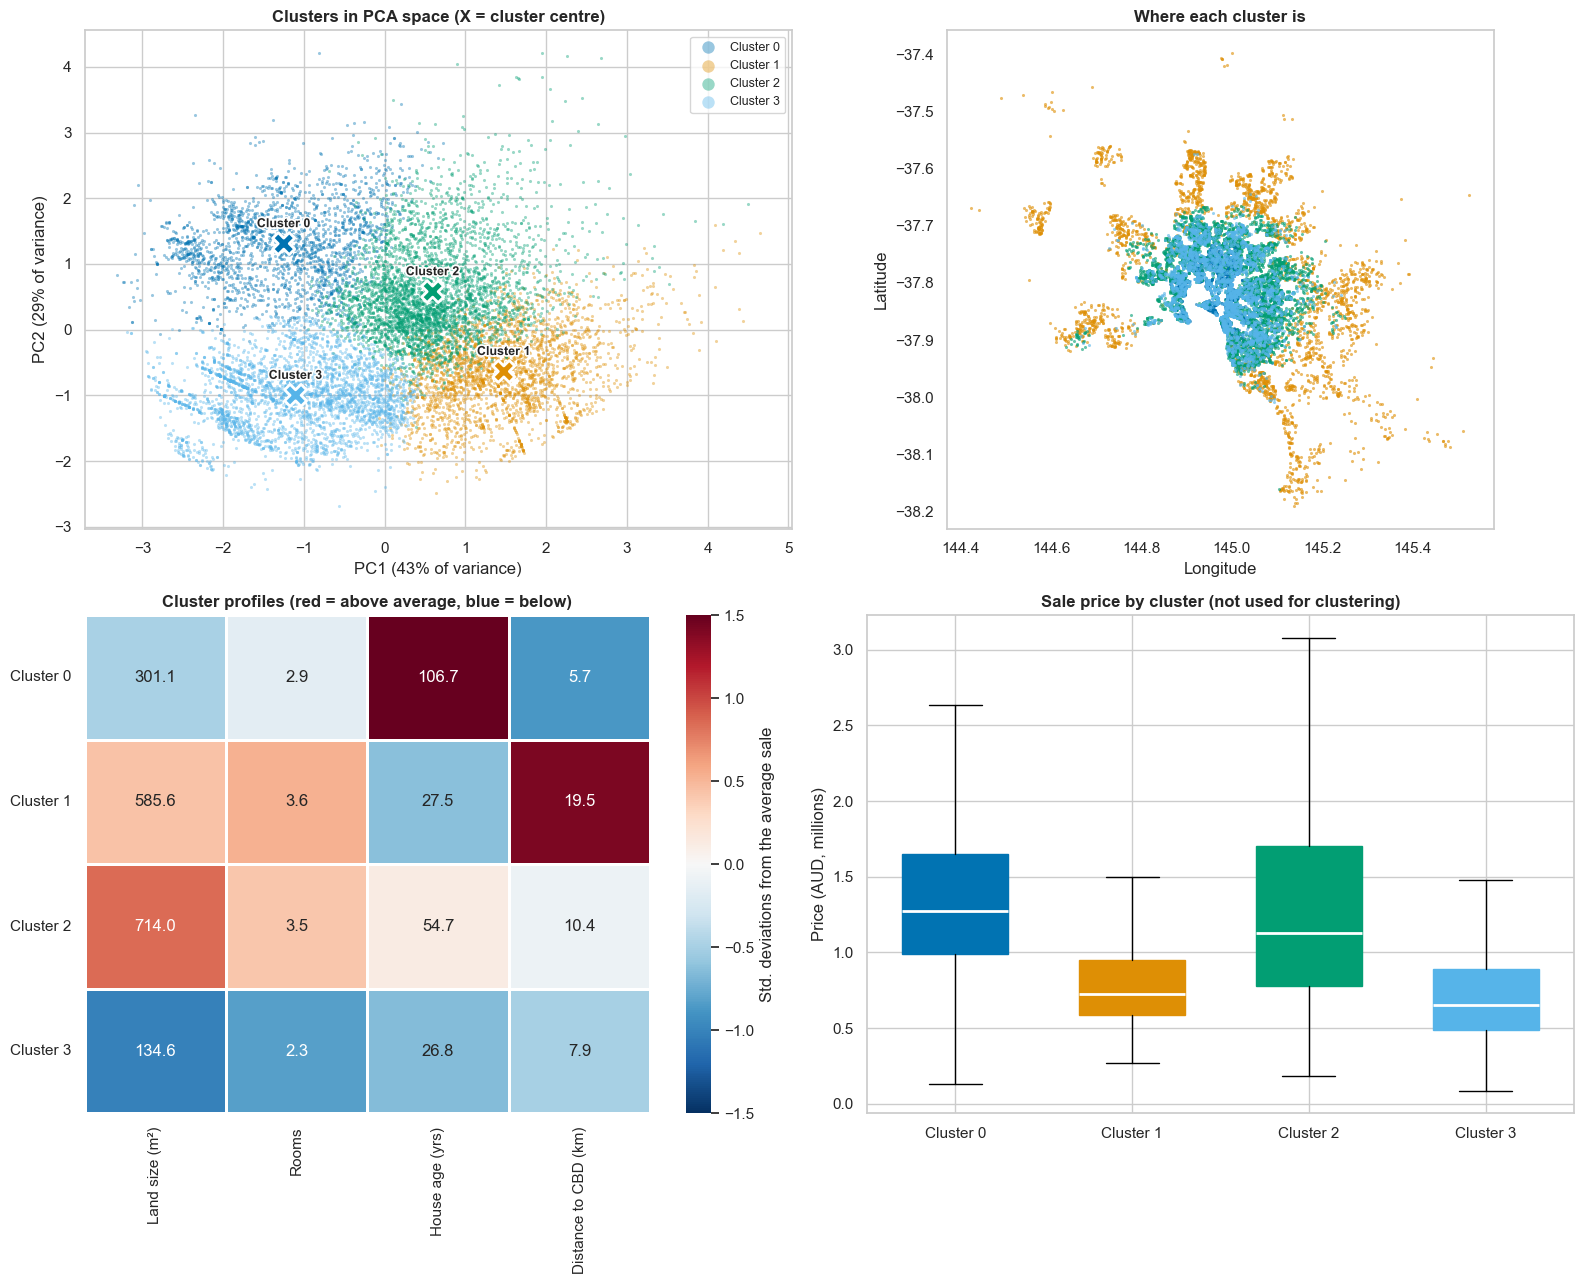

In [58]:
# Cluster overview: four views of the same clusters, one colour per cluster in every panel
#   1. PCA space - how K-Means split the data
#   2. Map       - where each cluster's sales are (location was NOT used for clustering)
#   3. Profile   - how each cluster differs from the average sale, feature by feature
#   4. Price     - price per cluster (price was NOT used for clustering either)
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

k = kmeans.n_clusters
cluster_names = [f"Cluster {i}" for i in range(k)]
colors = CAT_PALETTE[:k]
data = df_clean.loc[X.index]                 # same rows, same order as X_pca
labels = data["cluster"].to_numpy()

fig, axes = plt.subplots(2, 2, figsize=(16, 13))
ax_pca, ax_map, ax_profile, ax_price = axes.flatten()

# 1. PCA space: each sale by its first two component scores, cluster centres marked with X
for i, (name, color) in enumerate(zip(cluster_names, colors)):
    mask = labels == i
    ax_pca.scatter(X_pca[mask, 0], X_pca[mask, 1], s=5, alpha=0.4, linewidths=0,
                   color=color, label=name)
centers = kmeans.cluster_centers_
ax_pca.scatter(centers[:, 0], centers[:, 1], marker="X", s=250, c=colors,
               edgecolors="white", linewidths=2, zorder=3)
for i, (x, y) in enumerate(centers[:, :2]):
    ax_pca.text(x, y + 0.25, cluster_names[i], ha="center", fontsize=9,
                fontweight="bold", path_effects=OUTLINE)
pc_var = pca.explained_variance_ratio_
ax_pca.set_xlabel(f"PC1 ({pc_var[0]:.0%} of variance)")
ax_pca.set_ylabel(f"PC2 ({pc_var[1]:.0%} of variance)")
ax_pca.set_title("Clusters in PCA space (X = cluster centre)", fontweight="bold")
ax_pca.legend(markerscale=4, fontsize=9)

# 2. Map: real locations, coloured by cluster
for i, color in enumerate(colors):
    part = data[labels == i]
    ax_map.scatter(part["Longitude"], part["Latitude"], s=5, alpha=0.6,
                   linewidths=0, color=color)
ax_map.set_aspect(1 / np.cos(np.radians(data["Latitude"].mean())))   # keeps the map unstretched
ax_map.set_xlabel("Longitude")
ax_map.set_ylabel("Latitude")
ax_map.set_title("Where each cluster is", fontweight="bold")
ax_map.grid(False)

# 3. Profile heatmap: colour = how far the cluster mean is from the overall mean
#    (in standard deviations); the number in each cell is the real mean value
#    .astype(float) turns pandas nullable Int64/Float64 columns into plain floats,
#    which seaborn's heatmap needs
features = data[numeric_features].astype(float)
means = features.groupby(data["cluster"]).mean()
z_scores = (means - features.mean()) / features.std()
sns.heatmap(z_scores, annot=means.to_numpy(), fmt=".1f", cmap="RdBu_r", center=0,
            vmin=-1.5, vmax=1.5, linewidths=2, linecolor="white", ax=ax_profile,
            yticklabels=cluster_names,
            xticklabels=["Land size (m²)", "Rooms", "House age (yrs)", "Distance to CBD (km)"],
            cbar_kws={"label": "Std. deviations from the average sale"})
ax_profile.set_ylabel("")
ax_profile.set_title("Cluster profiles (red = above average, blue = below)", fontweight="bold")
ax_profile.tick_params(axis="y", rotation=0)

# 4. Price by cluster: box = middle 50% of prices, white line = median
prices = [data.loc[labels == i, "Price"] / 1e6 for i in range(k)]
boxes = ax_price.boxplot(prices, patch_artist=True, showfliers=False, widths=0.6,
                         medianprops={"color": "white", "linewidth": 2})
for box, color in zip(boxes["boxes"], colors):
    box.set_facecolor(color)
    box.set_edgecolor(color)
ax_price.set_xticks(range(1, k + 1), cluster_names)
ax_price.set_ylabel("Price (AUD, millions)")
ax_price.set_title("Sale price by cluster (not used for clustering)", fontweight="bold")
ax_price.grid(axis="y", visible=True)

plt.tight_layout()
save_fig("19_cluster_overview")
plt.show()


To effectively visualize the property clusters, we have to look at them from two angles: how they separate in the reduced PCA space, and what physical characteristics define them in the original feature space.

Python code using matplotlib and seaborn to generate two clear visual representations:

Scatter Plot in PCA Space (Showing Cluster Boundaries & Centers)

This plot shows how your properties group along your primary principal components (e.g., PC1 vs. PC2), with the K-Means cluster centers marked with an X.

Figure saved to figures\20_pca_clusters.png


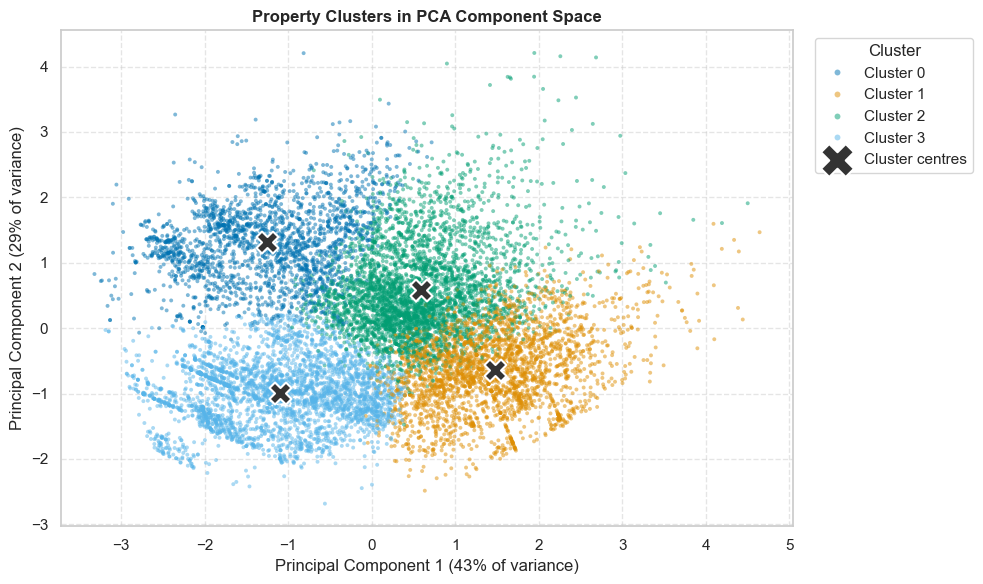

In [59]:
# Property clusters in PCA space: each sale by its first two component scores,
# coloured by K-Means cluster, with the cluster centres marked
import matplotlib.pyplot as plt
import seaborn as sns

k = kmeans.n_clusters
cluster_names = [f"Cluster {i}" for i in range(k)]
# .to_numpy() so the labels match X_pca by position (df_clean's index is not 0..n-1)
hue_labels = df_clean.loc[X.index, "cluster"].map(dict(enumerate(cluster_names))).to_numpy()
pc_var = pca.explained_variance_ratio_

plt.figure(figsize=(10, 6))

# Scatter of data points coloured by cluster
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=hue_labels,
    hue_order=cluster_names,
    palette=CAT_PALETTE[:k],   # same cluster colours as the overview figure
    alpha=0.5,
    edgecolor="none",
    s=8,                       # ~12,000 points: small dots so dense areas stay readable
)

# K-Means cluster centres (dark X with a white edge, so it shows on every cluster colour)
centers = kmeans.cluster_centers_
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    c=INK,
    s=250,
    marker="X",
    edgecolors="white",
    linewidths=1.5,
    label="Cluster centres",
    zorder=3,
)

plt.xlabel(f"Principal Component 1 ({pc_var[0]:.0%} of variance)")
plt.ylabel(f"Principal Component 2 ({pc_var[1]:.0%} of variance)")
plt.title("Property Clusters in PCA Component Space", fontweight="bold")
plt.legend(title="Cluster", markerscale=1.5, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
save_fig("20_pca_clusters")
plt.show()


Feature Distribution Across Clusters (Boxplots)Because PCA components can sometimes feel abstract, boxplots let you instantly see how the clusters break down by your original real estate features (like square_footage and distance_from_cbd).

Figure saved to figures\21_cluster_feature_boxplots.png


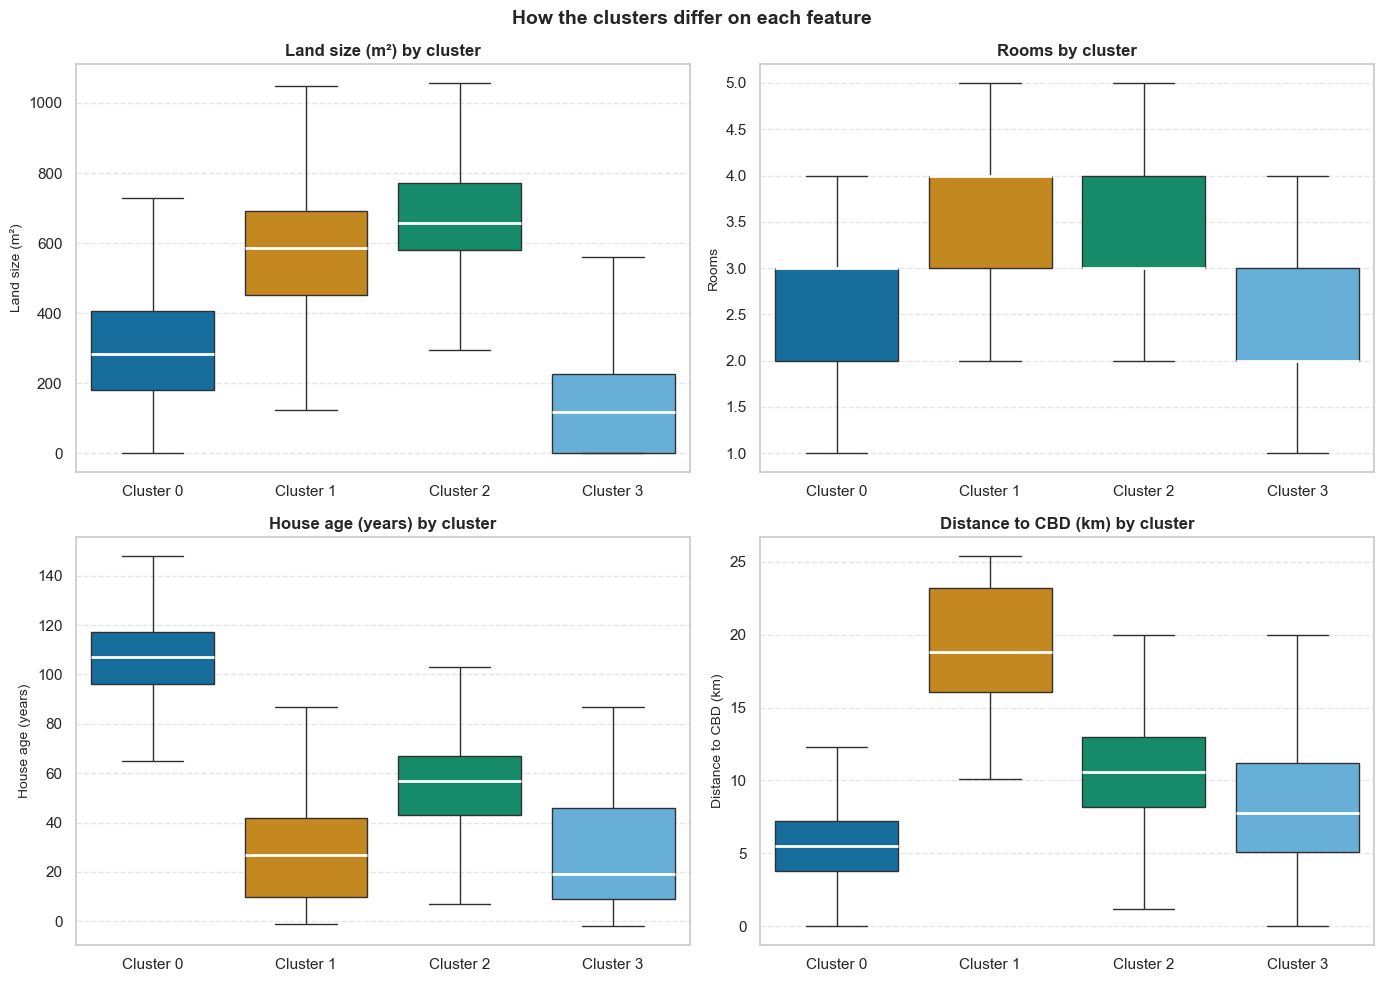

In [60]:
# Distribution of each clustering feature by cluster
# Box = middle 50% of sales, line = median, whiskers = typical range (outliers hidden)
import matplotlib.pyplot as plt
import seaborn as sns

k = kmeans.n_clusters
cluster_names = [f"Cluster {i}" for i in range(k)]
feature_labels = {
    "Landsize": "Land size (m²)",
    "Rooms": "Rooms",
    "HouseAge": "House age (years)",
    "Distance": "Distance to CBD (km)",
}

# Plain floats (nullable Int64 columns break seaborn) plus a readable cluster name column
plot_data = df_clean.loc[X.index, numeric_features].astype(float)
plot_data["Cluster"] = df_clean.loc[X.index, "cluster"].map(dict(enumerate(cluster_names)))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, feature in zip(axes.flatten(), numeric_features):
    sns.boxplot(
        data=plot_data,
        x="Cluster",
        y=feature,
        hue="Cluster",              # hue + legend=False: one colour per cluster without a warning
        order=cluster_names,
        hue_order=cluster_names,
        palette=CAT_PALETTE[:k],    # same cluster colours as the other cluster figures
        legend=False,
        showfliers=False,           # hide outlier dots so the boxes are easy to compare
        medianprops={"color": "white", "linewidth": 2},
        ax=ax,
    )
    ax.set_title(f"{feature_labels[feature]} by cluster", fontsize=12, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel(feature_labels[feature], fontsize=10)
    ax.grid(axis="y", linestyle="--", alpha=0.5)

fig.suptitle("How the clusters differ on each feature", fontsize=14, fontweight="bold")
plt.tight_layout()
save_fig("21_cluster_feature_boxplots")
plt.show()


While the exact labels depend on the numerical profile of your specific dataset, a real estate dataset clustered using square footage, room count, building age, and distance from the CBD naturally breaks down into four distinct housing archetypes.

Here are four professional, intuitive labels you can map to your clusters based on how their feature means (cluster_profiles) typically align:


Urban Core Condos / Compact ApartmentsProfile: Very low distance from CBD, lower square footage, and fewer rooms. Building age may vary (historic core vs. modern infill).


Principal Component Signature: Heavily weighted toward the negative end of the CBD distance axis and smaller property scales.

The Narrative: These represent high-density, inner-city living spaces designed for accessibility and location convenience over sprawling square footage.


Established Mid-Ring Family HomesProfile: Moderate distance from CBD, moderate-to-high square footage, and a higher building age (established neighborhoods built decades ago).


Principal Component Signature: Sits comfortably in the middle of the PCA space—representing the classic "suburban transition zone" surrounding the urban core.

The Narrative: Traditional, stable neighborhoods offering a balance of living space and reasonable commuting distance.


Sprawling Suburban EstatesProfile: High distance from CBD, maximum square footage, maximum room counts, and typically newer construction phases.


Principal Component Signature: Anchors the extreme positive end of size/room dimensions and high distance from the center.

The Narrative: Outer-ring or peripheral suburban developments built for space, multi-car garages, and large yards.


Prime Central / Premium Urban ResidencesProfile: Low-to-moderate distance from CBD combined with unusually high square footage or high room counts.


Principal Component Signature: An outlier cluster in PCA space that defies the typical trade-off where properties near the center must be small.

The Narrative: High-value townhomes, large historic properties close to the city center, or luxury urban developments.

How to Assign These Labels Programmatically in Python
Once you inspect your cluster_profiles DataFrame (the mean values of each feature per cluster), you can map these labels directly back to your dataframe:

Example: Map cluster IDs to descriptive labels based on your inspection of cluster_profilescluster_mapping = {
0: 'Established Mid-Ring Family Homes',
1: 'Urban Core Condos',
2: 'Sprawling Suburban Estates',
3: 'Prime Central Residences'
}

df['cluster_label'] = df['cluster'].map(cluster_mapping)
Check the count of properties in each labeled clusterprint(df['cluster_label'].value_counts())

--- Cluster labels ---


,label,sales,Landsize,Rooms,HouseAge,Distance,median_price_M
cluster,,,,,,,
0,Inner-city older mid-size houses,2154,301.10,2.90,106.70,5.70,1.27
1,Outer-suburb newer large houses,2759,585.60,3.60,27.50,19.50,0.72
2,Middle-ring mid-size houses,3852,714.00,3.50,54.70,10.40,1.12
3,Inner-city newer small units,3313,134.60,2.30,26.80,7.90,0.66


Figure saved to figures\22_pca_clusters_labelled.png


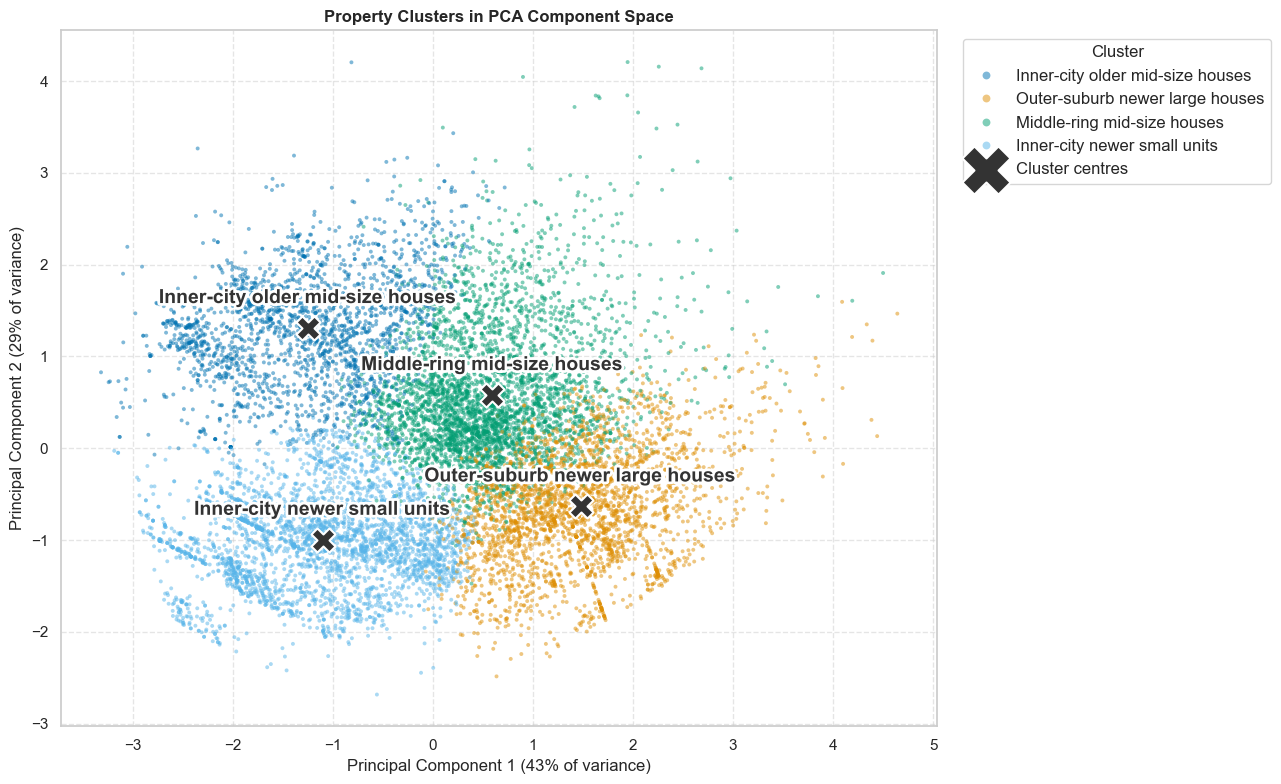

In [61]:
# Give each cluster a readable name based on its profile, then redraw the PCA cluster plot
import matplotlib.pyplot as plt
import seaborn as sns

k = kmeans.n_clusters
data = df_clean.loc[X.index]
features = data[numeric_features].astype(float)   # plain floats (nullable Int64 breaks the maths)
labels = data["cluster"].to_numpy()

# How far each cluster's mean is from the overall mean, in standard deviations
means = features.groupby(labels).mean()
z_scores = (means - features.mean()) / features.std()

THRESHOLD = 0.5   # more than half a standard deviation from average counts as "different"

def describe(z, low, mid, high):
    # Pick a word depending on whether the cluster is below, near or above average
    return low if z < -THRESHOLD else high if z > THRESHOLD else mid

def name_cluster(i):
    z = z_scores.loc[i]
    location = describe(z["Distance"], "Inner-city", "Middle-ring", "Outer-suburb")
    size = describe(z["Rooms"], "small", "mid-size", "large")
    age = describe(z["HouseAge"], "newer", "", "older")
    top_type = type_names.get(str(data.loc[labels == i, "Type"].mode().iat[0]), "home")
    return " ".join(word for word in [location, age, size, f"{top_type.lower()}s"] if word)

# Use the names from the cluster_profile naming cell (profile_names) when it has been run;
# otherwise fall back to the automatic names built from the z-scores above
if "profile_names" in globals():
    cluster_label_map = dict(profile_names)
else:
    cluster_label_map = {i: name_cluster(i) for i in range(k)}
    # Two clusters can end up with the same description: add the ID to tell them apart
    counts = pd.Series(cluster_label_map).value_counts()
    cluster_label_map = {i: f"{name} ({i})" if counts[name] > 1 else name
                         for i, name in cluster_label_map.items()}

# To overwrite any name with your own, uncomment and edit:
# cluster_label_map[0] = "Inner-city apartments"

df_clean.loc[X.index, "cluster_label"] = data["cluster"].map(cluster_label_map)

# Summary table: the name next to the numbers that produced it
summary = means.round(1)
summary.insert(0, "label", [cluster_label_map[i] for i in summary.index])
summary.insert(1, "sales", pd.Series(labels).value_counts().sort_index())
summary["median_price_M"] = data.groupby(labels)["Price"].median().div(1e6).round(2)
summary.index.name = "cluster"
print("--- Cluster labels ---")
display(summary)

# Property clusters in PCA space, now with names
label_order = [cluster_label_map[i] for i in range(k)]
pc_var = pca.explained_variance_ratio_

LABEL_SIZE = 14    # names next to the cluster centres
LEGEND_SIZE = 12   # names in the legend

plt.figure(figsize=(13, 8))
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=pd.Series(labels).map(cluster_label_map).to_numpy(),
    hue_order=label_order,
    palette=CAT_PALETTE[:k],
    alpha=0.5,
    edgecolor="none",
    s=8,
)

centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c=INK, s=300, marker="X",
            edgecolors="white", linewidths=1.5, label="Cluster centres", zorder=3)
# Name next to each centre (thicker white outline to match the bigger text)
for i, (x, y) in enumerate(centers[:, :2]):
    plt.annotate(cluster_label_map[i], (x, y), xytext=(0, 18), textcoords="offset points",
                 ha="center", fontsize=LABEL_SIZE, fontweight="bold", color=INK,
                 path_effects=[pe.withStroke(linewidth=4, foreground="white")], zorder=4)

plt.xlabel(f"Principal Component 1 ({pc_var[0]:.0%} of variance)")
plt.ylabel(f"Principal Component 2 ({pc_var[1]:.0%} of variance)")
plt.title("Property Clusters in PCA Component Space", fontweight="bold")
plt.legend(title="Cluster", fontsize=LEGEND_SIZE, title_fontsize=LEGEND_SIZE,
           markerscale=2, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
save_fig("22_pca_clusters_labelled")
plt.show()



1. Assign the raw K-Means cluster integers to your original dataframedf['cluster_id'] = kmeans.labels_
2. (Optional) Map the cluster IDs to your descriptive labelsAdjust the dictionary keys/values to match your cluster profiling resultscluster_mapping = {
0: 'Urban Core Condos',
1: 'Established Mid-Ring Family Homes',
2: 'Sprawling Suburban Estates',
3: 'Prime Central Residences'
}
df['cluster_label'] = df['cluster_id'].map(cluster_mapping)3. Preview the final dataset with the newly appended columnsprint(df[['square_footage', 'distance_from_cbd', 'cluster_id', 'cluster_label']].head(10))
4. Save your finalized dataset to diskdf.to_csv('homes_with_clusters.csv', index=False)
print("\nDataset successfully saved to 'homes_with_clusters.csv'")

In [62]:
# Final dataset: every cleaned sale with its cluster ID and cluster name, saved to disk

# 1. Raw K-Means cluster IDs, lined up with the cleaned rows the model was trained on
df_clean.loc[X.index, "cluster_id"] = kmeans.labels_
df_clean["cluster_id"] = df_clean["cluster_id"].astype("Int64")
df_clean = df_clean.drop(columns=["cluster"], errors="ignore")   # older copy of the same IDs

# 2. Descriptive names. Default: the automatic names from the labelling cell.
#    To use your own, set cluster_mapping to a dict, matching each ID to the summary table, e.g.
#    cluster_mapping = {0: "Urban Core Condos", 1: "Established Mid-Ring Family Homes",
#                       2: "Sprawling Suburban Estates", 3: "Prime Central Residences"}
cluster_mapping = profile_names   # names from the cluster_profile naming cell (None = automatic names)
if cluster_mapping is None:
    cluster_mapping = cluster_label_map
assert set(cluster_mapping) == set(range(kmeans.n_clusters)), "every cluster ID needs exactly one name"

df_clean["cluster_label"] = df_clean["cluster_id"].map(cluster_mapping)

print("--- Cluster names ---")
for cluster_id, name in cluster_mapping.items():
    n_sales = (df_clean["cluster_id"] == cluster_id).sum()
    print(f"  {cluster_id}: {name}  ({n_sales:,} sales)")

# 3. Preview the final dataset with the new columns
preview_cols = ["Suburb", "Type", "Price", "Rooms", "Landsize", "HouseAge", "Distance",
                "cluster_id", "cluster_label"]
print("\n--- Preview ---")
display(df_clean[preview_cols].head(10))

# 4. Save the finalized dataset (all cleaned columns + cluster_id + cluster_label)
clusters_path = DATASET_DIR / "melbourne_house_prices_with_clusters.csv"
df_clean.to_csv(clusters_path, index=False)
print(f"\nSaved {len(df_clean):,} rows and {df_clean.shape[1]} columns to {clusters_path}")


--- Cluster names ---
  0: Inner-city older mid-size houses  (2,154 sales)
  1: Outer-suburb newer large houses  (2,759 sales)
  2: Middle-ring mid-size houses  (3,852 sales)
  3: Inner-city newer small units  (3,313 sales)

--- Preview ---


,Suburb,Type,Price,Rooms,Landsize,HouseAge,Distance,cluster_id,cluster_label
2,Abbotsford,h,"1,035,000.00",2,156.00,116,2.50,0,Inner-city older mid-size houses
4,Abbotsford,h,"1,465,000.00",3,134.00,117,2.50,0,Inner-city older mid-size houses
6,Abbotsford,h,"1,600,000.00",4,120.00,2,2.50,3,Inner-city newer small units
11,Abbotsford,h,"1,876,000.00",3,245.00,106,2.50,0,Inner-city older mid-size houses
14,Abbotsford,h,"1,636,000.00",2,256.00,126,2.50,0,Inner-city older mid-size houses
18,Abbotsford,h,"1,097,000.00",2,220.00,116,2.50,0,Inner-city older mid-size houses
24,Abbotsford,h,"1,350,000.00",3,214.00,11,2.50,3,Inner-city newer small units
25,Abbotsford,u,"750,000.00",2,0.00,7,2.50,3,Inner-city newer small units
30,Abbotsford,h,"1,310,000.00",2,238.00,126,2.50,0,Inner-city older mid-size houses
32,Abbotsford,h,"1,200,000.00",3,113.00,136,2.50,0,Inner-city older mid-size houses



Saved 12,078 rows and 30 columns to ..\dataset\melbourne_house_prices_with_clusters.csv
